In [2]:
import cv2
import json
import numpy as np
import pandas as pd
import time
from datetime import datetime
from ultralytics import YOLO

In [ ]:
import cv2
import numpy as np

# Store clicked points
points = []
def click_event(event, x, y, flags, param):
    global frame_display
    if event == cv2.EVENT_LBUTTONDOWN:
        points.append((x, y))
        # Draw point
        cv2.circle(frame_display, (x, y), 5, (0, 0, 255), -1)
        # Draw line from previous point
        if len(points) > 1:
            cv2.line(frame_display, points[-2], points[-1], (0, 255, 0), 2)
        print(f"Point captured: ({x}, {y})")

# Load first frame
video_path = "main1.MOV"

cap = cv2.VideoCapture(video_path)


ret, frame = cap.read()

cap.release()

if not ret:
    print("Error loading video.")
    exit()

# Copy frame for drawing
frame_display = frame.copy()

cv2.namedWindow("ROI Selector")
cv2.setMouseCallback("ROI Selector", click_event)
print("Instructions:")
print(" - Left click to add points")
print(" - Press 'q' to finish")
print(" - Press 'c' to clear all points")

while True:
    cv2.imshow("ROI Selector", frame_display)

    key = cv2.waitKey(1) & 0xFF

    # Quit
    if key == ord('q'):

        # Close polygon automatically
        if len(points) > 2:
            cv2.line(
                frame_display,
                points[-1],
                points[0],
                (255, 0, 0),
                2
            )

        break

    # Clear everything
    elif key == ord('c'):
        points.clear()
        frame_display = frame.copy()
        print("Cleared all points")

cv2.destroyAllWindows()

print("\nCaptured ROI Points:")
print(points)

total_frames: 2019
67.355
Instructions:
 - Left click to add points
 - Press 'q' to finish
 - Press 'c' to clear all points

Captured ROI Points:
[]


In [ ]:
from datetime import datetime
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO

# ---------------------------------------------------------
# 1. CONFIGURATION & EXACT ROIs FROM YOUR CAPTURE
# ---------------------------------------------------------
VIDEO_PATH = "main1.MOV"  
OUTPUT_PATH = "annotated_main1_(5)_v10s_reid_output.mp4"  
CSV_LOG_PATH = "queue_event_log(5)_v10s_reid_output.csv" 

# Configured ROI polygons from your coordinates
QUEUE_ROI = np.array([(313, 497), (466, 462), (797, 599), (623, 683), (315, 499)], np.int32)
SERVICE_ROI = np.array([(294, 470), (393, 444), (421, 474), (326, 514), (290, 474)], np.int32)
STAFF_ROI = np.array([(243, 322), (252, 424), (383, 416), (365, 312), (243, 322)], np.int32)


MIN_QUEUE_DWELL_TIME = (1.0)
GRACE_PERIOD = (4.0)
MIN_SERVICE_TIME = 2.0


COLOR_QUEUE = (0, 255, 255)  # Yellow
COLOR_SERVICE = (0, 255, 0)  # Green
COLOR_PENDING = (0, 165, 255)  # Orange
COLOR_ABANDONED = (0, 0, 255)  # Red
COLOR_CANCELLED = (255, 191, 0)  # Sky Blue

# ---------------------------------------------------------
# RE-ID CONFIGURATION
# ---------------------------------------------------------
MAX_REID_DISTANCE = 60  # pixels
MAX_REID_TIME = 3.0  # seconds

lost_tracks = {}
id_mapping = {}

served_count = 0
abandoned_count = 0


def euclidean_distance(p1, p2):
    return np.linalg.norm(np.array(p1) - np.array(p2))


# ---------------------------------------------------------
# 2. STATE MACHINE DATA STRUCTURES
# ---------------------------------------------------------
track_history = {}
event_logs = []


def point_in_poly(point, polygon):
    return (cv2.pointPolygonTest(polygon, (float(point[0]), float(point[1])), False)>= 0)


# ---------------------------------------------------------
# 3. VIDEO PROCESSING & ANALYTICS PIPELINE
# ---------------------------------------------------------
model = YOLO("yolov8n.pt").to("cuda") 
cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
TRACK_MEMORY_SECONDS = 8

track_buffer = int(fps * TRACK_MEMORY_SECONDS)

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*"mp4v"), fps, (frame_width, frame_height))
print(f"Video FPS: {fps}")

print("Starting Queue Analytics Processing...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    current_time = (cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0)  
    results = model.track(frame,persist=True,classes=[0],tracker="custom_bytetrack.yaml",verbose=False,)
    cv2.polylines(frame, [QUEUE_ROI], isClosed=True, color=COLOR_QUEUE, thickness=2)
    cv2.putText(frame,"QUEUE ROI",(QUEUE_ROI[0][0], QUEUE_ROI[0][1] - 10),cv2.FONT_HERSHEY_SIMPLEX,0.5,COLOR_QUEUE,2)

    cv2.polylines(frame, [SERVICE_ROI], isClosed=True, color=COLOR_SERVICE, thickness=2)
    cv2.putText(frame,"SERVICE ROI",(SERVICE_ROI[0][0], SERVICE_ROI[0][1] - 10),cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLOR_SERVICE,2,)

    cv2.polylines(frame, [STAFF_ROI], isClosed=True, color=(255,105,180), thickness=2)
    cv2.putText(frame,"STAFF ROI",(STAFF_ROI[0][0], STAFF_ROI[0][1] - 10),cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,105,180), 2)

    current_frame_bt_ids = set()

    if results[0].boxes is not None and results[0].boxes.id is not None:
        boxes = results[0].boxes.xyxy.cpu().numpy()
        confidences = results[0].boxes.conf.cpu().numpy()
        track_ids = results[0].boxes.id.cpu().numpy().astype(int)

        for box, track_id, confidence in zip(boxes, track_ids, confidences):
            current_frame_bt_ids.add(track_id)

            x1, y1, x2, y2 = map(int, box)

            foot_x = (x1 + x2) // 2
            foot_y = y2

        
            head_x = (x1 + x2) // 2
            head_y = y1 + int((y2 - y1) * 0.2)

            

            # ============================
            # DISTANCE BASED RE-ID
            # ============================
            if track_id not in id_mapping:
                matched_old_id = None

                for old_id, info in list(lost_tracks.items()):
                    old_x, old_y = info["last_pos"]

                    dist = euclidean_distance((foot_x, foot_y), (old_x, old_y))
                    dt = current_time - info["last_time"]

                    if (dist < MAX_REID_DISTANCE and dt < MAX_REID_TIME and abs(foot_y - old_y) < 80):
                        matched_old_id = old_id
                        del lost_tracks[old_id]
                        break

                if matched_old_id is not None:
                    id_mapping[track_id] = matched_old_id
                else:
                    id_mapping[track_id] = track_id

            stable_id = id_mapping[track_id]

            in_queue = point_in_poly((foot_x, foot_y), QUEUE_ROI)
            in_service = point_in_poly((foot_x, foot_y), SERVICE_ROI)
            in_staff = point_in_poly((head_x, head_y), STAFF_ROI)

            if in_staff:
                cv2.rectangle(frame, (x1, y1), (x2, y2), (255,105,180), 2)

                cv2.putText(
                    frame,
                    "STAFF",
                    (x1, max(20, y1-10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255,105,180),
                    2
                )
                continue

            

            print(f"BT:{track_id} -> Stable:{stable_id}")

            if stable_id not in track_history:
                initial_zone = "SERVICE" if in_service else "OTHER"
                track_history[stable_id] = {
                    "state": "OUTSIDE_QUEUE",
                    "initial_zone": initial_zone,
                    "first_roi_entry": None,
                    "leave_time": None,
                    "service_entry_time": None,
                    "finalized": False,
                    "last_pos": (foot_x, foot_y),
                }

            record = track_history[stable_id]
            record["last_pos"] = (foot_x, foot_y)

            if record["finalized"]:
                continue
            if (record["initial_zone"] == "SERVICE" and record["first_roi_entry"] is None):
                continue

            # ==================================
            # STATE TRANSITION ENGINE
            # ==================================
            if in_service:
                if record["service_entry_time"] is None:
                    record["service_entry_time"] = current_time

                service_duration = current_time - record["service_entry_time"]

                if service_duration >= MIN_SERVICE_TIME:
                    record["state"] = "AT_SERVICE_POINT"
                    record["finalized"] = True
                    record["service_entry_time"] = None
                    wait_duration = current_time - (
                        record["first_roi_entry"] or current_time
                    )

                    event_logs.append(
                        {
                            "timestamp": datetime.now().strftime("%H:%M:%S"),
                            "track_id": stable_id,
                            "queue_duration_sec": round(wait_duration, 2),
                            "outcome": "SERVED",
                        }
                    )

                    served_count += 1

            elif in_queue:
                if record["first_roi_entry"] is None:
                    record["first_roi_entry"] = current_time

                dwell_duration = current_time - record["first_roi_entry"]

                if dwell_duration >= MIN_QUEUE_DWELL_TIME:
                    if record["state"] == "PENDING_ABANDONMENT":
                        record["state"] = "CANCELLED"
                        record["leave_time"] = None
                    elif record["state"] != "CANCELLED":
                        record["state"] = "IN_QUEUE"

            else:
                record["service_entry_time"] = None
                if record["state"] in ["IN_QUEUE", "CANCELLED"]:
                    record["state"] = "PENDING_ABANDONMENT"
                    record["leave_time"] = current_time

                elif record["state"] == "PENDING_ABANDONMENT":
                    time_elapsed = current_time - record["leave_time"]

                    if time_elapsed >= GRACE_PERIOD:
                        record["state"] = "ABANDONED"
                        record["finalized"] = True

                        wait_duration = (
                            record["leave_time"] - record["first_roi_entry"]
                        )

                        event_logs.append(
                            {
                                "timestamp": datetime.now().strftime(
                                    "%H:%M:%S"
                                ),
                                "track_id": stable_id,
                                "queue_duration_sec": round(wait_duration, 2),
                                "outcome": "ABANDONED",
                            }
                        )
                        abandoned_count += 1

            # ============================
            # DISPLAY
            # ============================
            box_color = (200, 200, 200)

            if record["state"] == "IN_QUEUE":
                box_color = COLOR_QUEUE
            elif record["state"] == "AT_SERVICE_POINT":
                box_color = COLOR_SERVICE
            elif record["state"] == "PENDING_ABANDONMENT":
                box_color = COLOR_PENDING
            elif record["state"] == "ABANDONED":
                box_color = COLOR_ABANDONED
            elif record["state"] == "CANCELLED":
                box_color = COLOR_CANCELLED

            cv2.rectangle(frame, (x1, y1), (x2, y2), box_color, 2)
            cv2.circle(frame, (foot_x, foot_y), 4, (0, 0, 255), -1)

            confidence_pct = confidence * 100

            label = (
                f"ID:{stable_id} | "
                f"{record['state']} | "
                f"Person: {confidence_pct:.1f}%"
            )

            if record["state"] == "PENDING_ABANDONMENT":
                remaining = max(0.0, GRACE_PERIOD - (current_time - record["leave_time"]))
                label += f" ({remaining:.1f}s)"

            cv2.putText(frame,label,(x1, max(20, y1 - 10)),cv2.FONT_HERSHEY_SIMPLEX,0.5, box_color,2)

    # ============================
    # LOST TRACK REGISTRATION
    # ============================
    for bt_id, stable_id in list(id_mapping.items()):
        if bt_id not in current_frame_bt_ids:
            if stable_id in track_history:
                record = track_history[stable_id]
                lost_tracks[stable_id] = {
                    "last_pos": record["last_pos"],
                    "last_time": current_time,
                }
            del id_mapping[bt_id]

    # CLEANUP
    for stable_id in list(lost_tracks.keys()):
        if (
            current_time - lost_tracks[stable_id]["last_time"]
        ) > MAX_REID_TIME:
            del lost_tracks[stable_id]

    # Dashboard Background
    cv2.rectangle(frame, (10, 10), (320, 120), (40, 40, 40), -1)

    # Served Count
    cv2.putText(frame,f"Served: {served_count}",(20, 50),cv2.FONT_HERSHEY_SIMPLEX,0.8,(0, 255, 0),2)

    # Abandoned Count
    cv2.putText(
        frame,
        f"Abandoned: {abandoned_count}",
        (20, 90),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2,
    )

    out.write(frame)

cap.release()
out.release()
cv2.destroyAllWindows()

# Export event logs to CSV
df = pd.DataFrame(event_logs)
df.to_csv(CSV_LOG_PATH, index=False)

print(
    f"\nExecution Finished!\nOutput Video: {OUTPUT_PATH}\nEvent Logs: {CSV_LOG_PATH}"
)




Video FPS: 29.975502932224778
Starting Queue Analytics Processing...
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stable:1
BT:1 -> Stabl

In [ ]:

from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import supervision as sv

from rfdetr import RFDETRMedium
from trackers import ByteTrackTracker


# ---------------------------------------------------------
# 1. CONFIGURATION & EXACT ROIs FROM YOUR CAPTURE
# ---------------------------------------------------------
VIDEO_PATH = "main1.MOV"
OUTPUT_PATH = "annotated_main1_(5)_rfdetr_medium_output.mp4"
CSV_LOG_PATH = "queue_event_log(5)_rfdetr_medium.csv"

QUEUE_ROI = np.array(
    [(313, 497), (466, 462), (797, 599), (623, 683), (315, 499)],
    np.int32
)

SERVICE_ROI = np.array(
    [(294, 470), (393, 444), (421, 474), (326, 514), (290, 474)],
    np.int32
)

STAFF_ROI = np.array(
    [(243, 322), (252, 424), (383, 416), (365, 312), (243, 322)],
    np.int32
)

# Configurable Parameters
MIN_QUEUE_DWELL_TIME = 1.0
GRACE_PERIOD = 4.0
MIN_SERVICE_TIME = 2.0

# UI Display Colors (BGR format)
COLOR_QUEUE = (0, 255, 255)
COLOR_SERVICE = (0, 255, 0)
COLOR_PENDING = (0, 165, 255)
COLOR_ABANDONED = (0, 0, 255)
COLOR_CANCELLED = (255, 191, 0)

# ---------------------------------------------------------
# RF-DETR CONFIGURATION
# ---------------------------------------------------------
PERSON_CLASS_ID = 1
DETECTION_THRESHOLD = 0.10

# ---------------------------------------------------------
# RE-ID CONFIGURATION
# ---------------------------------------------------------
MAX_REID_DISTANCE = 60
MAX_REID_TIME = 3.0

lost_tracks = {}
id_mapping = {}

served_count = 0
abandoned_count = 0


def euclidean_distance(p1, p2):
    return np.linalg.norm(np.array(p1) - np.array(p2))


# ---------------------------------------------------------
# 2. STATE MACHINE DATA STRUCTURES
# ---------------------------------------------------------
track_history = {}
event_logs = []
staff_track_ids = set()


def point_in_poly(point, polygon):
    """Check if a point falls inside an ROI polygon."""
    return (
        cv2.pointPolygonTest(
            polygon,
            (float(point[0]), float(point[1])),
            False
        ) >= 0
    )


# ---------------------------------------------------------
# 3. MODEL, TRACKER & VIDEO INITIALIZATION
# ---------------------------------------------------------
print("Loading RF-DETR Medium...")
model = RFDETRMedium()


tracker = ByteTrackTracker(
    track_activation_threshold=DETECTION_THRESHOLD,
    minimum_consecutive_frames=1
)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise FileNotFoundError(
        f"Could not open video: {VIDEO_PATH}"
    )

fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = 30.0

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter(
    OUTPUT_PATH,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (frame_width, frame_height)
)

if not out.isOpened():
    cap.release()
    raise RuntimeError(
        f"Could not create output video: {OUTPUT_PATH}"
    )

print("Starting RF-DETR Queue Analytics Processing...")

try:
    while cap.isOpened():
        ret, frame = cap.read()

        if not ret:
            break

        current_time = (
            cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0
        )

        # -------------------------------------------------
        # 4. RF-DETR PERSON DETECTION
        # -------------------------------------------------
       
        detections = model.predict(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
            threshold=DETECTION_THRESHOLD
        )

        # Keep person detections only.
        person_mask = (
            detections.class_id == PERSON_CLASS_ID
        )
        person_detections = detections[person_mask]

        # -------------------------------------------------
        # 5. BYTE TRACK TRACKING
        # -------------------------------------------------
        # Returns sv.Detections with tracker_id assigned.
        tracked_detections = tracker.update(
            person_detections
        )

        current_frame_bt_ids = set()

        # -------------------------------------------------
        # 6. DRAW ROIs
        # -------------------------------------------------
        cv2.polylines(
            frame,
            [QUEUE_ROI],
            isClosed=True,
            color=COLOR_QUEUE,
            thickness=2
        )
        cv2.putText(
            frame,
            "QUEUE ROI",
            (QUEUE_ROI[0][0], QUEUE_ROI[0][1] - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            COLOR_QUEUE,
            2
        )

        cv2.polylines(
            frame,
            [SERVICE_ROI],
            isClosed=True,
            color=COLOR_SERVICE,
            thickness=2
        )
        cv2.putText(
            frame,
            "SERVICE ROI",
            (SERVICE_ROI[0][0], SERVICE_ROI[0][1] - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            COLOR_SERVICE,
            2
        )

        cv2.polylines(
            frame,
            [STAFF_ROI],
            isClosed=True,
            color=(255, 105, 180),
            thickness=2
        )
        cv2.putText(
            frame,
            "STAFF ROI",
            (STAFF_ROI[0][0], STAFF_ROI[0][1] - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 105, 180),
            2
        )

        # -------------------------------------------------
        # 7. PROCESS TRACKED PEOPLE
        # -------------------------------------------------
        if (
            tracked_detections.xyxy is not None
            and tracked_detections.tracker_id is not None
        ):
            boxes = tracked_detections.xyxy
            confidences = tracked_detections.confidence
            track_ids = tracked_detections.tracker_id

            for box, track_id, confidence in zip(
                boxes,
                track_ids,
                confidences
            ):
                if track_id is None or int(track_id) < 0:
                    continue

                track_id = int(track_id)
                current_frame_bt_ids.add(track_id)

                x1, y1, x2, y2 = map(int, box)

                foot_x = (x1 + x2) // 2
                foot_y = y2

                head_x = (x1 + x2) // 2
                head_y = y1 + int((y2 - y1) * 0.2)

                # =========================================
                # DISTANCE-BASED RE-ID
                # =========================================
                if track_id not in id_mapping:
                    matched_old_id = None

                    for old_id, info in list(
                        lost_tracks.items()
                    ):
                        old_x, old_y = info["last_pos"]

                        dist = euclidean_distance(
                            (foot_x, foot_y),
                            (old_x, old_y)
                        )

                        dt = current_time - info["last_time"]

                        if (
                            dist < MAX_REID_DISTANCE
                            and dt < MAX_REID_TIME
                            and abs(foot_y - old_y) < 80
                        ):
                            matched_old_id = old_id
                            del lost_tracks[old_id]
                            break

                    if matched_old_id is not None:
                        id_mapping[track_id] = matched_old_id
                    else:
                        id_mapping[track_id] = track_id

                stable_id = id_mapping[track_id]

                in_queue = point_in_poly(
                    (foot_x, foot_y),
                    QUEUE_ROI
                )

                in_service = point_in_poly(
                    (foot_x, foot_y),
                    SERVICE_ROI
                )

                in_staff = point_in_poly(
                    (head_x, head_y),
                    STAFF_ROI
                )

                print(
                    f"BT:{track_id} -> Stable:{stable_id}"
                )

                # =========================================
                # INITIALIZE TRACK HISTORY
                # =========================================
                if stable_id not in track_history:
                    initial_zone = (
                        "SERVICE" if in_service else "OTHER"
                    )

                    track_history[stable_id] = {
                        "state": "OUTSIDE_QUEUE",
                        "initial_zone": initial_zone,
                        "first_roi_entry": None,
                        "leave_time": None,
                        "service_entry_time": None,
                        "finalized": False,
                        "last_pos": (foot_x, foot_y),
                    }

                record = track_history[stable_id]
                record["last_pos"] = (foot_x, foot_y)

                if record["finalized"]:
                    continue

                if (
                    record["initial_zone"] == "SERVICE"
                    and record["first_roi_entry"] is None
                ):
                    continue

                # =========================================
                # STATE TRANSITION ENGINE
                # Original logic retained
                # =========================================
                if in_service:
                    if record["service_entry_time"] is None:
                        record["service_entry_time"] = (
                            current_time
                        )

                    service_duration = (
                        current_time
                        - record["service_entry_time"]
                    )

                    if service_duration >= MIN_SERVICE_TIME:
                        record["state"] = "AT_SERVICE_POINT"
                        record["finalized"] = True
                        record["service_entry_time"] = None

                        wait_duration = current_time - (
                            record["first_roi_entry"]
                            or current_time
                        )

                        event_logs.append({
                            "timestamp": datetime.now().strftime(
                                "%H:%M:%S"
                            ),
                            "track_id": stable_id,
                            "queue_duration_sec": round(
                                wait_duration, 2
                            ),
                            "outcome": "SERVED",
                        })

                        served_count += 1

                elif in_queue:
                    if record["first_roi_entry"] is None:
                        record["first_roi_entry"] = current_time

                    dwell_duration = (
                        current_time
                        - record["first_roi_entry"]
                    )

                    if dwell_duration >= MIN_QUEUE_DWELL_TIME:
                        if (
                            record["state"]
                            == "PENDING_ABANDONMENT"
                        ):
                            record["state"] = "CANCELLED"
                            record["leave_time"] = None

                        elif record["state"] != "CANCELLED":
                            record["state"] = "IN_QUEUE"

                else:
                    record["service_entry_time"] = None

                    if record["state"] in [
                        "IN_QUEUE",
                        "CANCELLED"
                    ]:
                        record["state"] = (
                            "PENDING_ABANDONMENT"
                        )
                        record["leave_time"] = current_time

                    elif (
                        record["state"]
                        == "PENDING_ABANDONMENT"
                    ):
                        time_elapsed = (
                            current_time - record["leave_time"]
                        )

                        if time_elapsed >= GRACE_PERIOD:
                            record["state"] = "ABANDONED"
                            record["finalized"] = True

                            wait_duration = (
                                record["leave_time"]
                                - record["first_roi_entry"]
                            )

                            event_logs.append({
                                "timestamp": datetime.now().strftime(
                                    "%H:%M:%S"
                                ),
                                "track_id": stable_id,
                                "queue_duration_sec": round(
                                    wait_duration, 2
                                ),
                                "outcome": "ABANDONED",
                            })

                            abandoned_count += 1

                # =========================================
                # DISPLAY
                # =========================================
                box_color = (200, 200, 200)

                if record["state"] == "IN_QUEUE":
                    box_color = COLOR_QUEUE

                elif record["state"] == "AT_SERVICE_POINT":
                    box_color = COLOR_SERVICE

                elif record["state"] == "PENDING_ABANDONMENT":
                    box_color = COLOR_PENDING

                elif record["state"] == "ABANDONED":
                    box_color = COLOR_ABANDONED

                elif record["state"] == "CANCELLED":
                    box_color = COLOR_CANCELLED

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    box_color,
                    2
                )

                cv2.circle(
                    frame,
                    (foot_x, foot_y),
                    4,
                    (0, 0, 255),
                    -1
                )

                confidence_pct = float(confidence) * 100

                label = (
                    f"ID:{stable_id} | "
                    f"{record['state']} | "
                    f"Person: {confidence_pct:.1f}%"
                )

                if record["state"] == "PENDING_ABANDONMENT":
                    remaining = max(
                        0.0,
                        GRACE_PERIOD
                        - (
                            current_time
                            - record["leave_time"]
                        )
                    )
                    label += f" ({remaining:.1f}s)"

                cv2.putText(
                    frame,
                    label,
                    (x1, max(20, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    box_color,
                    2
                )

        # ================================================
        # LOST TRACK REGISTRATION
        # ================================================
        for bt_id, stable_id in list(id_mapping.items()):
            if bt_id not in current_frame_bt_ids:
                if stable_id in track_history:
                    record = track_history[stable_id]

                    lost_tracks[stable_id] = {
                        "last_pos": record["last_pos"],
                        "last_time": current_time,
                    }

                del id_mapping[bt_id]

        # CLEANUP
        for stable_id in list(lost_tracks.keys()):
            if (
                current_time
                - lost_tracks[stable_id]["last_time"]
            ) > MAX_REID_TIME:
                del lost_tracks[stable_id]

        # ================================================
        # DASHBOARD
        # ================================================
        cv2.rectangle(
            frame,
            (10, 10),
            (320, 120),
            (40, 40, 40),
            -1
        )

        cv2.putText(
            frame,
            f"Served: {served_count}",
            (20, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            f"Abandoned: {abandoned_count}",
            (20, 90),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        out.write(frame)

finally:
    cap.release()
    out.release()
    cv2.destroyAllWindows()

    # Export event logs to CSV
    df = pd.DataFrame(
        event_logs,
        columns=[
            "timestamp",
            "track_id",
            "queue_duration_sec",
            "outcome",
        ]
    )

    df.to_csv(CSV_LOG_PATH, index=False)

print(
    f"\nExecution Finished!"
    f"\nOutput Video: {OUTPUT_PATH}"
    f"\nEvent Logs: {CSV_LOG_PATH}"
    f"\nServed: {served_count}"
    f"\nAbandoned: {abandoned_count}"
)


Loading RF-DETR Medium...
[2026-10-29 17:20:39] [INFO] rf-detr - File C:\Users\elgin\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-29 17:20:39] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-29 17:20:39] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-29 17:20:40] [INFO] rf-detr - File C:\Users\elgin\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.
Starting RF-DETR Queue Analytics Processing...


[2026-10-29 17:20:41] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable:0
BT:1 -> Stable:1
BT:0 -> Stable

In [3]:
import cv2
#annotated_main1_(5)_v10n_output.mp4
#annotated_main1_(5)_v8n_output.mp4
video_path = "annotated_main1_(5)_v8n_output.mp4"  

cap = cv2.VideoCapture(video_path)

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    cv2.imshow("Video", frame)

    # Press q to quit
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [8]:
import cv2
from pathlib import Path

VIDEO_PATH = "main1.MOV"
OUTPUT_DIR = Path("dataset/images/all")
INTERVAL_SECONDS = 2

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 30

interval = max(1, int(fps * INTERVAL_SECONDS))
frame_index = 0
saved = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_index % interval == 0:
        timestamp = frame_index / fps
        filename = f"frame_{saved:05d}.jpg"

        cv2.imwrite(str(OUTPUT_DIR / filename), frame)
        saved += 1

    frame_index += 1

cap.release()

print(f"Extracted {saved} frames to {OUTPUT_DIR}")

Extracted 35 frames to dataset\images\all


In [ ]:
from pathlib import Path

YOLO_DIR = Path(r"E:\proglint\main1\cvat_yolo")
MOT_DIR = Path(r"E:\proglint\main1\cvat_mot")

VIDEO_PATH = Path(r"E:\proglint\main1\main1.MOV")

print("YOLO export exists:", YOLO_DIR.exists())
print("MOT export exists:", MOT_DIR.exists())
print("Video exists:", VIDEO_PATH.exists())

YOLO export exists: True
MOT export exists: True
Video exists: True


In [11]:
from pathlib import Path
from collections import Counter

# ---------- 1. Check YOLO export ----------
print("=" * 55)
print("YOLO EXPORT INSPECTION")
print("=" * 55)

names_file = YOLO_DIR / "obj.names"
data_file = YOLO_DIR / "obj.data"
train_file = YOLO_DIR / "train.txt"
yolo_data_dir = YOLO_DIR / "obj_train_data"

if names_file.exists():
    class_names = [
        line.strip()
        for line in names_file.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    print("Classes:", class_names)
else:
    print("obj.names not found")

if data_file.exists():
    print("\nobj.data contents:")
    print(data_file.read_text(encoding="utf-8"))

if train_file.exists():
    train_entries = [
        line.strip()
        for line in train_file.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    print("\nEntries in train.txt:", len(train_entries))

if yolo_data_dir.exists():
    files = [p for p in yolo_data_dir.iterdir() if p.is_file()]
    extensions = Counter(p.suffix.lower() for p in files)

    print("\nFiles in obj_train_data:", len(files))
    print("File types:", dict(extensions))
    print("Image count:", sum(
        extensions[ext] for ext in [".jpg", ".jpeg", ".png", ".bmp"]
    ))
    print("TXT count:", extensions[".txt"])

    label_files = sorted(yolo_data_dir.glob("*.txt"))
    print("\nFirst 3 annotation files:")

    for path in label_files[:3]:
        print(f"\n{path.name}")
        print(path.read_text(encoding="utf-8")[:1000] or "(empty label file)")

# ---------- 2. Check MOT ground truth ----------
print("\n" + "=" * 55)
print("MOT TRACKING GROUND TRUTH")
print("=" * 55)

mot_file = MOT_DIR / "gt" / "gt.txt"

if mot_file.exists():
    rows = []

    with mot_file.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                values = [v.strip() for v in line.split(",")]
                rows.append(values)

    print("MOT rows:", len(rows))

    if rows:
        print("\nFirst 5 MOT rows:")
        for row in rows[:5]:
            print(row)

        try:
            frame_numbers = [int(float(row[0])) for row in rows]
            track_ids = [int(float(row[1])) for row in rows]

            print("\nUnique frame numbers:", len(set(frame_numbers)))
            print("Minimum frame number:", min(frame_numbers))
            print("Maximum frame number:", max(frame_numbers))
            print("Unique track IDs:", len(set(track_ids)))
            print("Minimum track ID:", min(track_ids))
            print("Maximum track ID:", max(track_ids))
        except (ValueError, IndexError):
            print("MOT rows need format inspection before numeric analysis.")
else:
    print("gt.txt not found at:", mot_file)

YOLO EXPORT INSPECTION
Classes: ['person', 'staff']

obj.data contents:
classes = 2
train = data/train.txt
names = data/obj.names
backup = backup/


Entries in train.txt: 35

Files in obj_train_data: 35
File types: {'.txt': 35}
Image count: 0
TXT count: 35

First 3 annotation files:

frame_00000.txt
1 0.243117 0.552243 0.098797 0.172208


frame_00001.txt
1 0.244590 0.552243 0.095852 0.172208
0 0.712586 0.716799 0.108172 0.512792


frame_00002.txt
1 0.246059 0.552243 0.092914 0.172208
0 0.762734 0.748542 0.144813 0.502917
0 0.480789 0.638958 0.108172 0.382639


MOT TRACKING GROUND TRUTH
MOT rows: 149

First 5 MOT rows:
['1', '1', '247.96', '335.62', '126.46000000000001', '123.99000000000001', '1', '2', '1.0']
['2', '1', '251.73', '335.62', '122.69000000000003', '123.99000000000001', '1', '2', '1.0']
['2', '2', '842.88', '331.49', '138.46000000000004', '369.21000000000004', '1', '1', '1.0']
['3', '1', '255.49', '335.62', '118.93', '123.99000000000001', '1', '2', '1.0']
['3', '3', '883.62

In [13]:
from pathlib import Path
import shutil
import yaml
from collections import Counter

PROJECT_DIR = Path(r"E:\proglint\main1")

IMAGE_DIR = PROJECT_DIR / "dataset" / "images" / "all"
LABEL_DIR = PROJECT_DIR / "cvat_yolo" / "obj_train_data"

EVAL_DIR = PROJECT_DIR / "evaluation_dataset"
EVAL_IMAGES = EVAL_DIR / "images" / "val"
EVAL_LABELS = EVAL_DIR / "labels" / "val"

EVAL_IMAGES.mkdir(parents=True, exist_ok=True)
EVAL_LABELS.mkdir(parents=True, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
images = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

class_counts = Counter()
empty_labels = 0
converted_labels = 0

for image_path in images:
    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing label: {label_path}")

    # Copy image without changing it.
    shutil.copy2(image_path, EVAL_IMAGES / image_path.name)

    converted_lines = []

    for line_number, line in enumerate(
        label_path.read_text(encoding="utf-8").splitlines(), start=1
    ):
        if not line.strip():
            continue

        parts = line.split()

        if len(parts) != 5:
            raise ValueError(
                f"Invalid annotation in {label_path.name}, "
                f"line {line_number}: {line}"
            )

        original_class = int(parts[0])

        if original_class not in (0, 1):
            raise ValueError(
                f"Unexpected class {original_class} in {label_path.name}"
            )

        # Map person=0 and staff=1 to person=0.
        parts[0] = "0"
        converted_lines.append(" ".join(parts))

        class_counts[original_class] += 1
        converted_labels += 1

    if not converted_lines:
        empty_labels += 1

    (EVAL_LABELS / label_path.name).write_text(
        "\n".join(converted_lines) + ("\n" if converted_lines else ""),
        encoding="utf-8"
    )

data_yaml = {
    "path": str(EVAL_DIR),
    "val": "images/val",
    "names": {0: "person"},
}

yaml_path = EVAL_DIR / "data.yaml"
with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("Evaluation dataset prepared.")
print("Images copied:", len(images))
print("Original person annotations (class 0):", class_counts[0])
print("Original staff annotations (class 1):", class_counts[1])
print("Total converted person boxes:", converted_labels)
print("Images with no annotations:", empty_labels)
print("Dataset YAML:", yaml_path)

Evaluation dataset prepared.
Images copied: 35
Original person annotations (class 0): 114
Original staff annotations (class 1): 35
Total converted person boxes: 149
Images with no annotations: 0
Dataset YAML: E:\proglint\main1\evaluation_dataset\data.yaml


In [16]:
from ultralytics import YOLO
from pathlib import Path

PROJECT_DIR = Path(r"E:\proglint\main1")
EVAL_DIR = PROJECT_DIR / "evaluation_dataset"

model = YOLO("yolov8n.pt")

metrics = model.val(
    data=str(EVAL_DIR / "data.yaml"),
    split="val",
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    plots=True,
    project=str(PROJECT_DIR / "evaluation_results"),
    name="yolov8n",
    exist_ok=True
)

print("\n--- YOLOv8n Detection Metrics ---")
print(f"Precision:       {metrics.box.mp:.4f}")
print(f"Recall:          {metrics.box.mr:.4f}")
print(f"mAP@0.50:        {metrics.box.map50:.4f}")
print(f"mAP@0.50:0.95:   {metrics.box.map:.4f}")

Ultralytics 8.4.187  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 28.4±2.7 MB/s, size: 175.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\proglint\main1\evaluation_dataset\labels\val... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35 355.6it/s 0.1s
val: New cache created: E:\proglint\main1\evaluation_dataset\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 9.8it/s 0.9s<0.2s
                   all         35        149       0.83      0.687      0.766      0.362
                person         35        149       0.83      0.687      0.766      0.362
Speed: 0.7ms preprocess, 11.2ms inference, 0.0ms los

Results directory exists: True

Saved files:
BoxF1_curve.png
BoxP_curve.png
BoxPR_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

Displaying available plots:

confusion_matrix.png


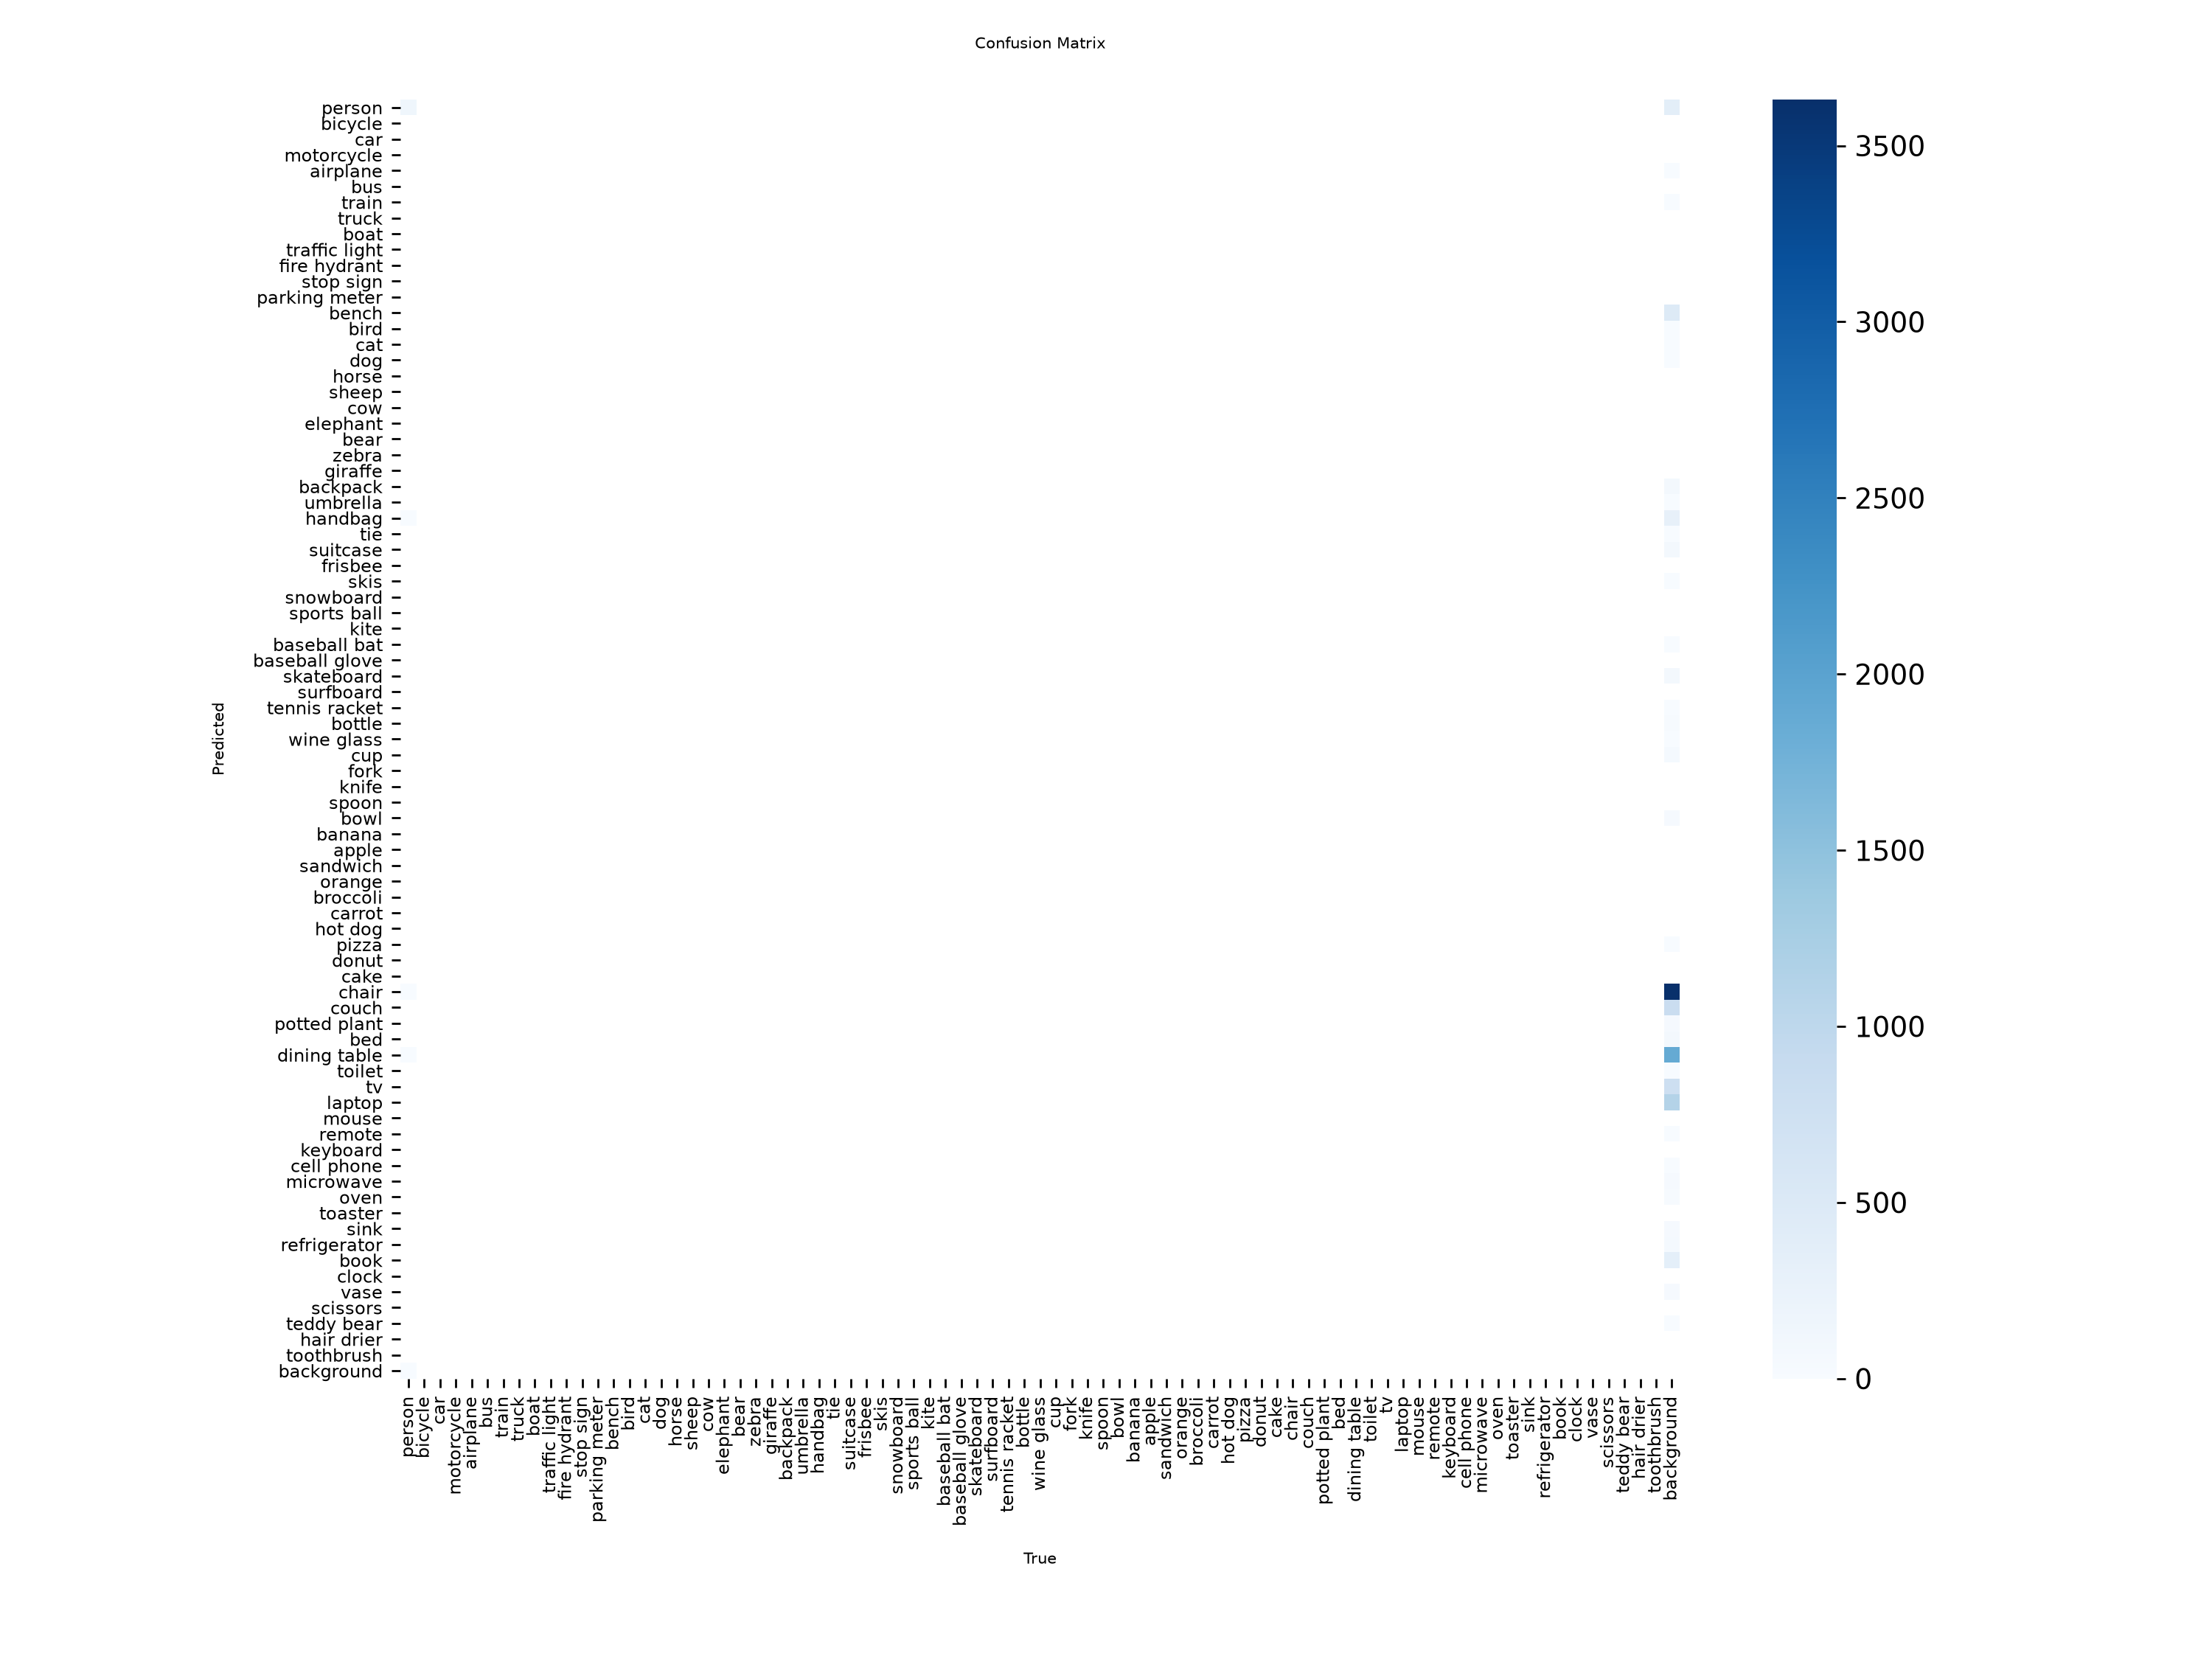


confusion_matrix_normalized.png


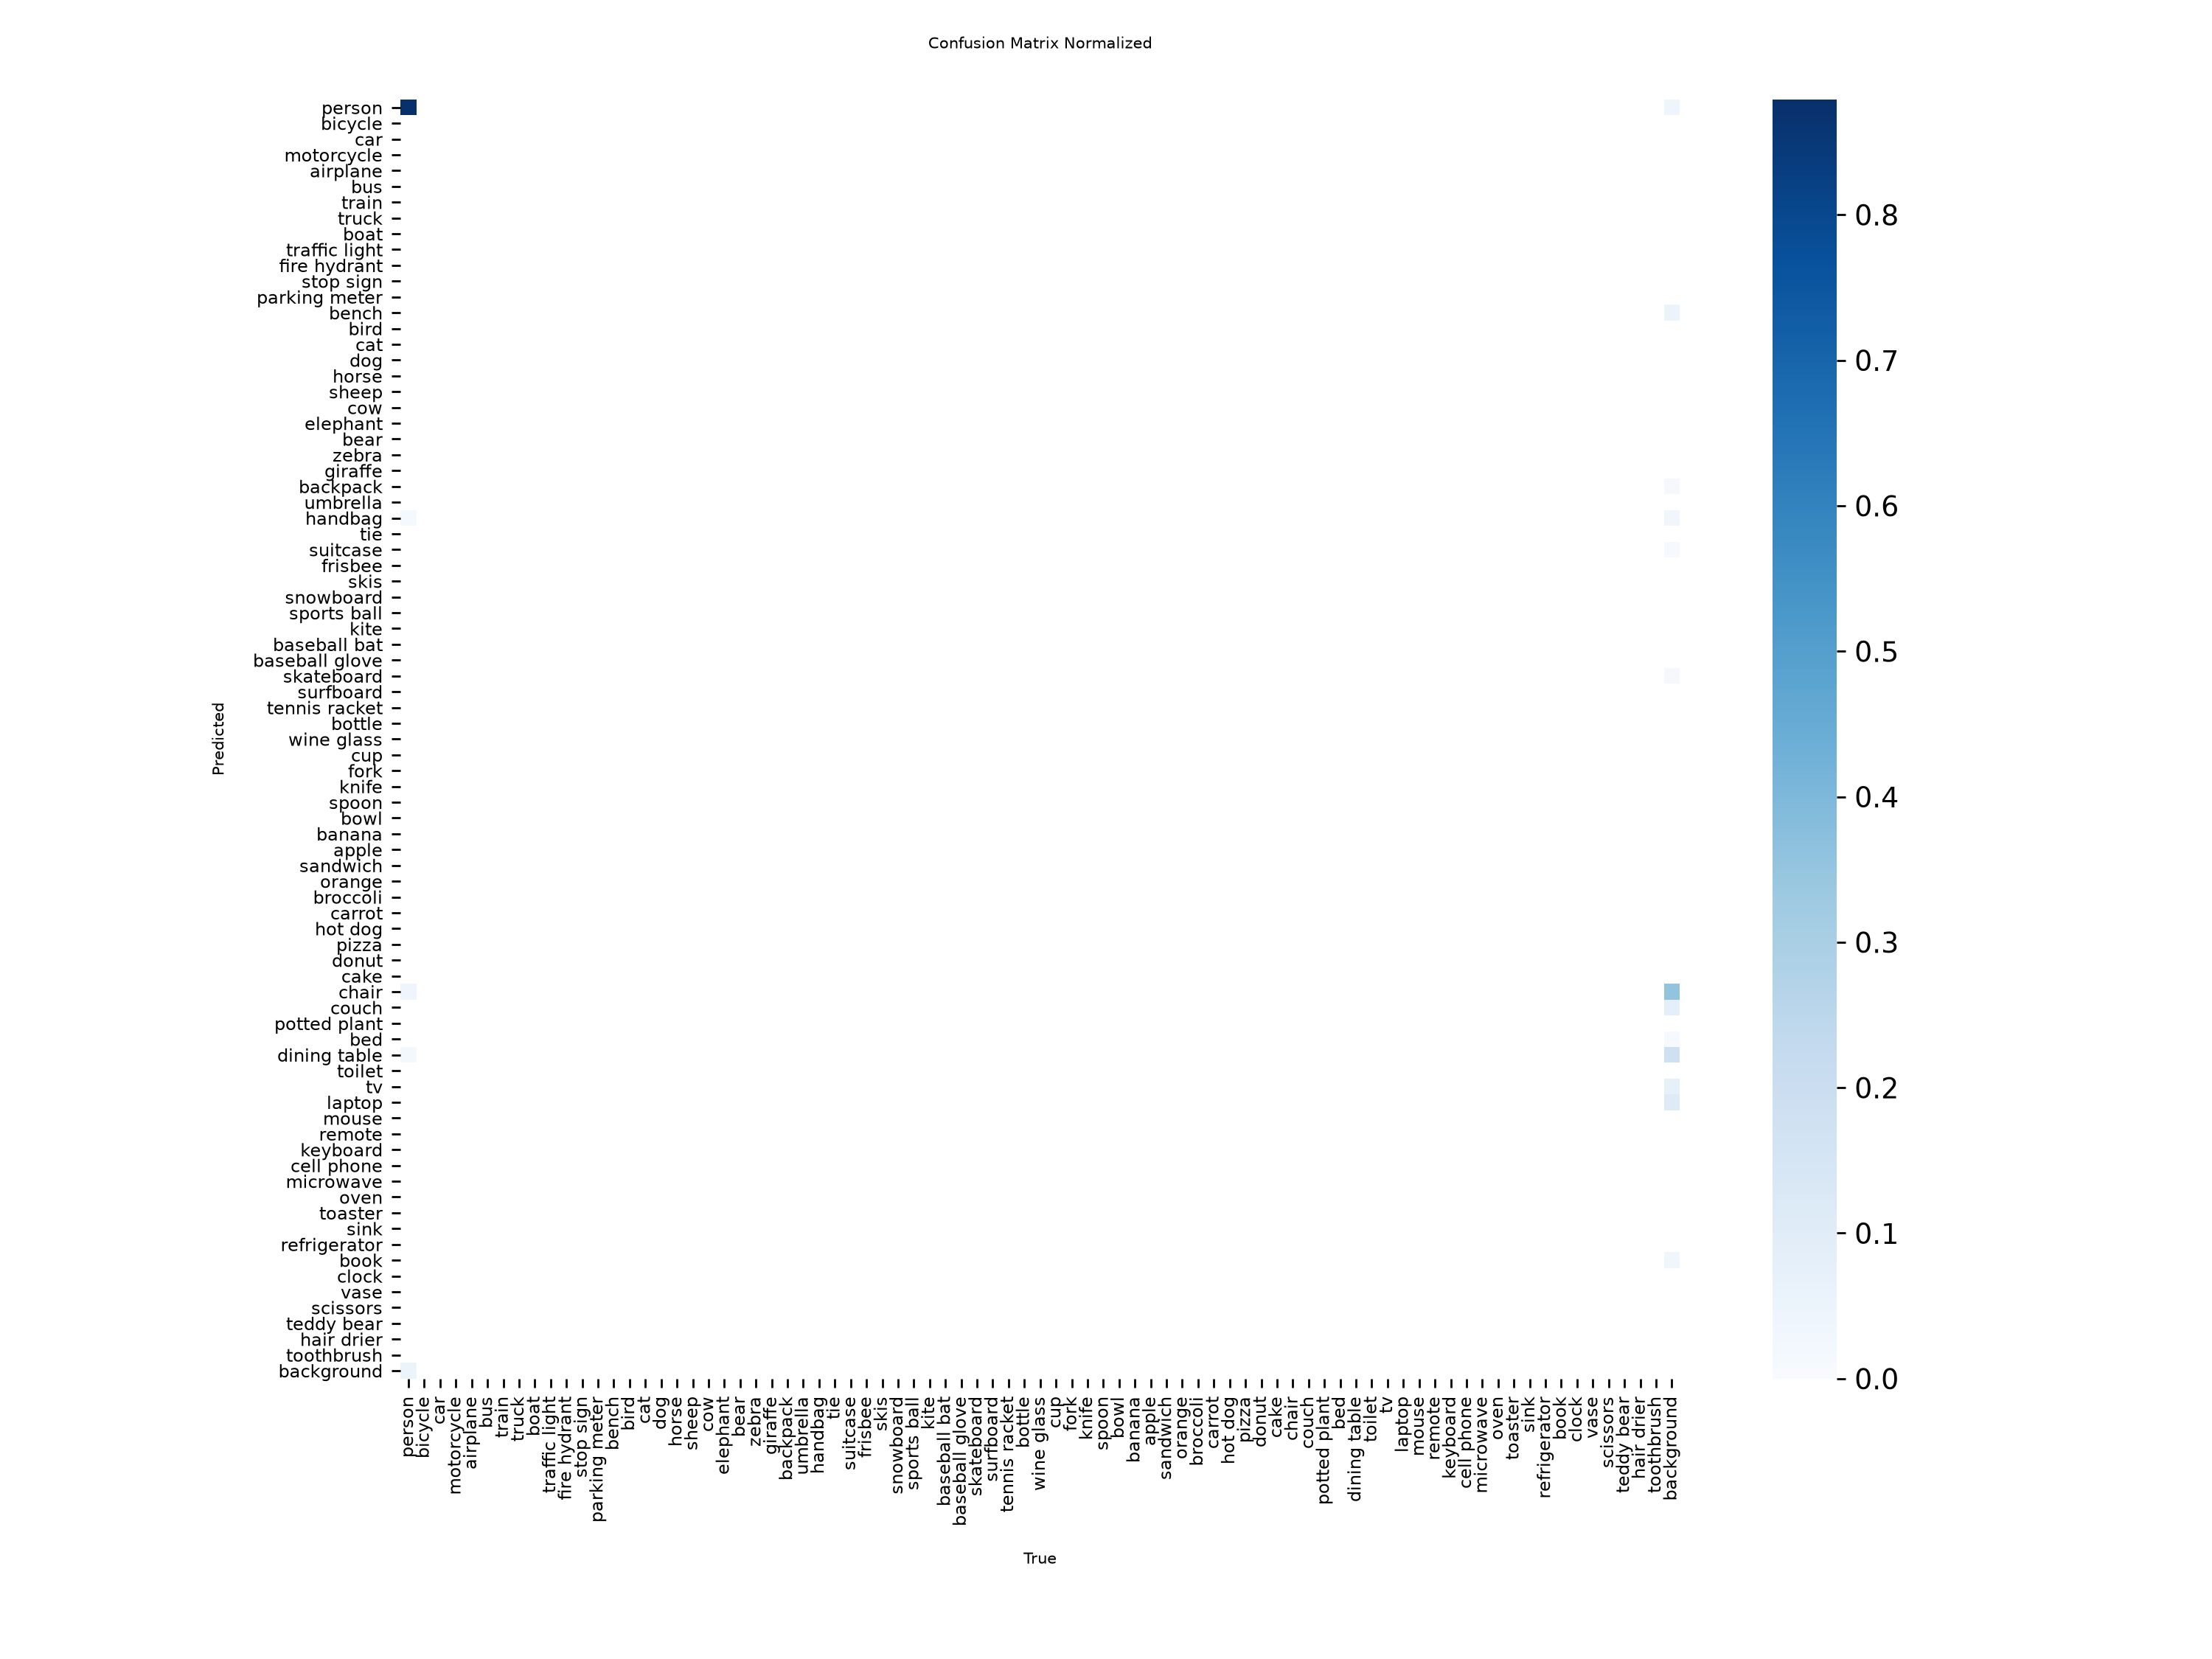


val_batch0_labels.jpg


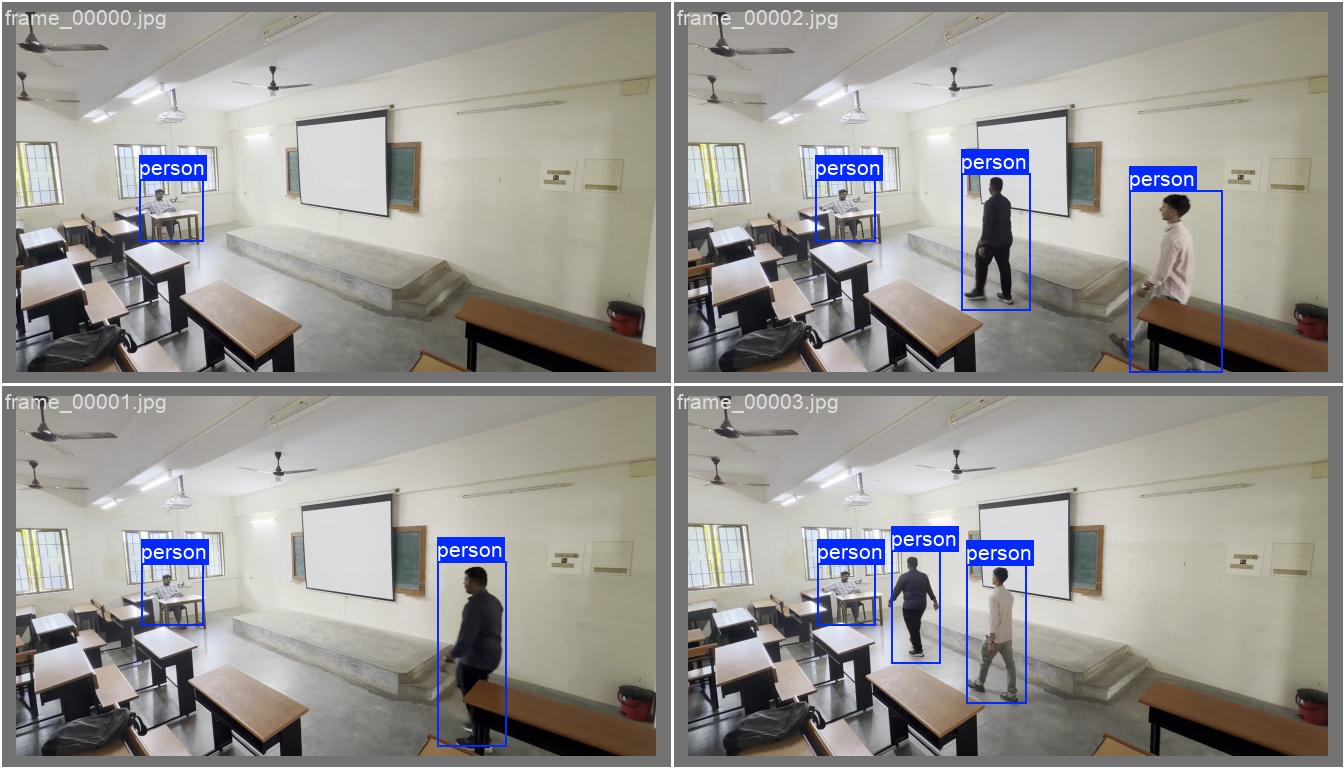


val_batch0_pred.jpg


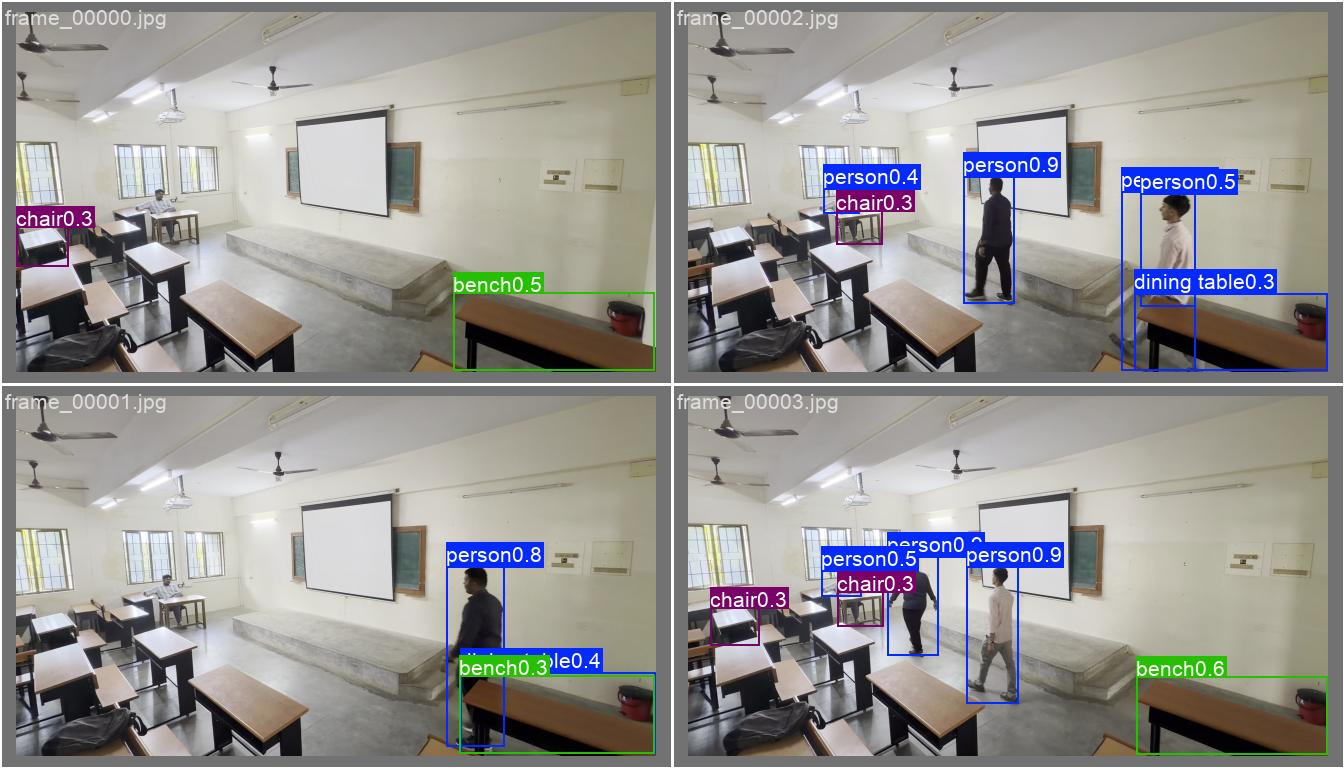

In [17]:

from pathlib import Path
from IPython.display import display, Image

RESULTS_DIR = Path(
    r"E:\proglint\main1\evaluation_results\yolov8n"
)

print("Results directory exists:", RESULTS_DIR.exists())

if RESULTS_DIR.exists():
    files = sorted(p for p in RESULTS_DIR.iterdir() if p.is_file())

    print("\nSaved files:")
    for file in files:
        print(file.name)

    # Display key evaluation plots
    plot_names = [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png",
        "PR_curve.png",
        "P_curve.png",
        "R_curve.png",
        "F1_curve.png",
        "val_batch0_labels.jpg",
        "val_batch0_pred.jpg",
    ]

    print("\nDisplaying available plots:")

    for name in plot_names:
        path = RESULTS_DIR / name

        if path.exists():
            print(f"\n{name}")
            display(Image(filename=str(path), width=800))
else:
    print("Check the results path printed by Ultralytics.")


In [18]:

from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"E:\proglint\main1")
EVAL_DIR = PROJECT_DIR / "evaluation_dataset"

model = YOLO("yolov8n.pt")

metrics_person = model.val(
    data=str(EVAL_DIR / "data.yaml"),
    split="val",
    classes=[0],       # Only the COCO person class
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    plots=True,
    project=str(PROJECT_DIR / "evaluation_results"),
    name="yolov8n_person_only",
    exist_ok=True
)

print("\n--- YOLOv8n: Person-only evaluation ---")
print(f"Precision:       {metrics_person.box.mp:.4f}")
print(f"Recall:          {metrics_person.box.mr:.4f}")
print(f"mAP@0.50:        {metrics_person.box.map50:.4f}")
print(f"mAP@0.50:0.95:   {metrics_person.box.map:.4f}")

print("\nResults saved to:")
print(PROJECT_DIR / "evaluation_results" / "yolov8n_person_only")


Ultralytics 8.4.187  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1112.5±113.1 MB/s, size: 178.3 KB)
val: Scanning E:\proglint\main1\evaluation_dataset\labels\val.cache... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 14.2it/s 0.6s0.2s
                   all         35        149       0.83      0.687      0.766      0.362
                person         35        149       0.83      0.687      0.766      0.362
Speed: 0.4ms preprocess, 4.5ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to E:\proglint\main1\evaluation_results\yolov8n_person_only

--- YOLOv8n: Person-only evaluation ---
Precision:       0.8298
Recall:          0.6870
mAP@0.50:        0.7656
mAP@0.50:0.95

In [20]:

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import csv

PROJECT_DIR = Path(r"E:\proglint\main1")
IMAGE_DIR = PROJECT_DIR / "dataset" / "images" / "all"
MOT_FILE = PROJECT_DIR / "cvat_mot" / "gt" / "gt.txt"
CLASS_FILE = PROJECT_DIR / "cvat_mot" / "gt" / "labels.txt"

# Read class names
class_names = [
    line.strip()
    for line in CLASS_FILE.read_text(encoding="utf-8-sig").splitlines()
    if line.strip()
]

# Parse MOT rows
mot_rows = []

with MOT_FILE.open("r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    for row in reader:
        if not row:
            continue

        if len(row) < 6:
            raise ValueError(f"Unexpected MOT row: {row}")

        mot_rows.append({
            "frame": int(row[0]),
            "track_id": int(row[1]),
            "x": float(row[2]),
            "y": float(row[3]),
            "w": float(row[4]),
            "h": float(row[5]),
            "confidence": float(row[6]) if len(row) > 6 else None,
            "class_id": int(float(row[7])) if len(row) > 7 else None,
        })

frames = sorted(set(r["frame"] for r in mot_rows))
track_ids = sorted(set(r["track_id"] for r in mot_rows))
class_counts = Counter(r["class_id"] for r in mot_rows)
boxes_per_frame = Counter(r["frame"] for r in mot_rows)

print("MOT rows:", len(mot_rows))
print("MOT frames:", len(frames))
print("Frame range:", min(frames), "to", max(frames))
print("Unique track IDs:", len(track_ids), track_ids)
print("Class counts:", {
    class_names[c - 1] if c is not None and 1 <= c <= len(class_names)
    else str(c): count
    for c, count in class_counts.items()
})
print("Boxes per frame:", dict(sorted(boxes_per_frame.items())))

# Test the likely 1-based MOT -> 0-based image mapping
print("\n--- Frame alignment check ---")

alignment_ok = True

for mot_frame in frames:
    image_path = IMAGE_DIR / f"frame_{mot_frame - 1:05d}.jpg"

    if not image_path.exists():
        print(f"MISSING: MOT frame {mot_frame} -> {image_path.name}")
        alignment_ok = False
        continue

    with Image.open(image_path) as im:
        width, height = im.size

    frame_boxes = [r for r in mot_rows if r["frame"] == mot_frame]

    out_of_bounds = [
        r for r in frame_boxes
        if r["x"] < -1 or r["y"] < -1
        or r["x"] + r["w"] > width + 2
        or r["y"] + r["h"] > height + 2
        or r["w"] <= 0 or r["h"] <= 0
    ]

    if out_of_bounds:
        print(
            f"CHECK: frame {mot_frame}, image {image_path.name}, "
            f"{len(out_of_bounds)} boxes outside image bounds"
        )
        alignment_ok = False

print("\nAll mapped images exist and boxes are within bounds:", alignment_ok)

print("\n--- First 10 MOT rows ---")
for r in mot_rows[:10]:
    print(r)


MOT rows: 149
MOT frames: 35
Frame range: 1 to 35
Unique track IDs: 10 [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Class counts: {'staff': 35, 'person': 114}
Boxes per frame: {1: 1, 2: 2, 3: 3, 4: 3, 5: 4, 6: 5, 7: 5, 8: 5, 9: 6, 10: 6, 11: 7, 12: 7, 13: 7, 14: 6, 15: 6, 16: 7, 17: 7, 18: 6, 19: 4, 20: 4, 21: 4, 22: 4, 23: 4, 24: 4, 25: 3, 26: 4, 27: 4, 28: 3, 29: 4, 30: 4, 31: 3, 32: 2, 33: 2, 34: 2, 35: 1}

--- Frame alignment check ---

All mapped images exist and boxes are within bounds: True

--- First 10 MOT rows ---
{'frame': 1, 'track_id': 1, 'x': 247.96, 'y': 335.62, 'w': 126.46000000000001, 'h': 123.99000000000001, 'confidence': 1.0, 'class_id': 2}
{'frame': 2, 'track_id': 1, 'x': 251.73, 'y': 335.62, 'w': 122.69000000000003, 'h': 123.99000000000001, 'confidence': 1.0, 'class_id': 2}
{'frame': 2, 'track_id': 2, 'x': 842.88, 'y': 331.49, 'w': 138.46000000000004, 'h': 369.21000000000004, 'confidence': 1.0, 'class_id': 1}
{'frame': 3, 'track_id': 1, 'x': 255.49, 'y': 335.62, 'w': 118.93, 'h

In [21]:


PROJECT_DIR = Path(r"E:\proglint\main1")
IMAGE_DIR = PROJECT_DIR / "dataset" / "images" / "all"
OUTPUT_CSV = PROJECT_DIR / "evaluation_results" / "bytetrack_predictions.csv"

image_paths = [
    IMAGE_DIR / f"frame_{i:05d}.jpg"
    for i in range(35)
]

missing = [str(p) for p in image_paths if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing images: {missing[:5]}")

model = YOLO("yolov8n.pt")

predictions = []
frames_with_tracks = 0

for index, image_path in enumerate(image_paths, start=1):
    # persist=True carries tracker state into the next image.
    result = model.track(
        source=str(image_path),
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],       # COCO person class only
        conf=0.10,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    if result.boxes is None or result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    track_ids = result.boxes.id.int().cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    class_ids = result.boxes.cls.int().cpu().numpy()

    if len(track_ids):
        frames_with_tracks += 1

    for box, track_id, confidence, class_id in zip(
        boxes, track_ids, confidences, class_ids
    ):
        x1, y1, x2, y2 = map(float, box)

        predictions.append({
            "frame": index,   # MOT frame numbering starts at 1
            "track_id": int(track_id),
            "x": x1,
            "y": y1,
            "w": x2 - x1,
            "h": y2 - y1,
            "confidence": float(confidence),
            "class_id": int(class_id)
        })

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

with OUTPUT_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "frame", "track_id", "x", "y", "w", "h",
        "confidence", "class_id"
    ])
    writer.writeheader()
    writer.writerows(predictions)

print("ByteTrack prediction complete.")
print("Images processed:", len(image_paths))
print("Frames with tracked detections:", frames_with_tracks)
print("Predicted boxes:", len(predictions))
print("Unique predicted track IDs:", len(set(
    row["track_id"] for row in predictions
)))
print("Saved predictions:", OUTPUT_CSV)

print("\nFirst 10 predictions:")
for row in predictions[:10]:
    print(row)


ByteTrack prediction complete.
Images processed: 35
Frames with tracked detections: 33
Predicted boxes: 93
Unique predicted track IDs: 10
Saved predictions: E:\proglint\main1\evaluation_results\bytetrack_predictions.csv

First 10 predictions:
{'frame': 3, 'track_id': 1, 'x': 874.2085571289062, 'y': 355.642578125, 'w': 117.09393310546875, 'h': 358.64404296875, 'confidence': 0.595587432384491, 'class_id': 0}
{'frame': 4, 'track_id': 3, 'x': 553.8335571289062, 'y': 338.8099670410156, 'w': 108.4986572265625, 'h': 269.6125793457031, 'confidence': 0.8812047839164734, 'class_id': 0}
{'frame': 4, 'track_id': 5, 'x': 269.4819641113281, 'y': 349.4995422363281, 'w': 75.49264526367188, 'h': 51.675201416015625, 'confidence': 0.46323344111442566, 'class_id': 0}
{'frame': 5, 'track_id': 5, 'x': 258.25225830078125, 'y': 343.26190185546875, 'w': 92.18325805664062, 'h': 63.2789306640625, 'confidence': 0.20481088757514954, 'class_id': 0}
{'frame': 5, 'track_id': 6, 'x': 405.1683044433594, 'y': 325.210693

In [27]:

from pathlib import Path
import csv
import pandas as pd
import motmetrics as mm

PROJECT_DIR = Path(r"E:\proglint\main1")
GT_FILE = PROJECT_DIR / "cvat_mot" / "gt" / "gt.txt"
PRED_FILE = PROJECT_DIR / "evaluation_results" / "bytetrack_predictions.csv"

# Load ground truth
gt_rows = []

with GT_FILE.open("r", encoding="utf-8-sig", newline="") as f:
    for row in csv.reader(f):
        if not row:
            continue

        gt_rows.append({
            "frame": int(row[0]),
            "track_id": int(row[1]),
            "x": float(row[2]),
            "y": float(row[3]),
            "w": float(row[4]),
            "h": float(row[5]),
        })

gt = pd.DataFrame(gt_rows)
pred = pd.read_csv(PRED_FILE)

# Automatic frame numbering is enabled.
acc = mm.MOTAccumulator(auto_id=True)

for frame in range(1, 36):
    g = gt[gt.frame == frame]
    p = pred[pred.frame == frame]

    gt_ids = g["track_id"].astype(int).tolist()
    pred_ids = p["track_id"].astype(int).tolist()

    gt_boxes = g[["x", "y", "w", "h"]].to_numpy(dtype=float)
    pred_boxes = p[["x", "y", "w", "h"]].to_numpy(dtype=float)

    distances = mm.distances.iou_matrix(
        gt_boxes,
        pred_boxes,
        max_iou=0.50
    )

    # Explicit frame IDs are not required with auto_id=True.
    acc.update(gt_ids, pred_ids, distances)

metrics_to_report = [
    "num_frames",
    "num_objects",
    "num_predictions",
    "num_matches",
    "num_misses",
    "num_false_positives",
    "num_switches",
    "mota",
    "motp",
    "idf1",
    "idp",
    "idr",
]

summary = mm.metrics.create().compute(
    acc,
    metrics=metrics_to_report,
    name="ByteTrack"
)

print("--- ByteTrack Tracking Evaluation ---")
print(summary.T.to_string())

output_path = PROJECT_DIR / "evaluation_results" / "bytetrack_metrics.csv"
summary.to_csv(output_path)
print("\nMetrics saved to:", output_path)


--- ByteTrack Tracking Evaluation ---
                      ByteTrack
num_frames            35.000000
num_objects          149.000000
num_predictions       93.000000
num_matches           60.000000
num_misses            69.000000
num_false_positives   13.000000
num_switches          20.000000
mota                   0.315436
motp                   0.279353
idf1                   0.330579
idp                    0.430108
idr                    0.268456

Metrics saved to: E:\proglint\main1\evaluation_results\bytetrack_metrics.csv


In [28]:
#botsort tracking evaluation

# 1. Paths
PROJECT_DIR = Path(r"E:\proglint\main1")
IMAGE_DIR = PROJECT_DIR / "dataset" / "images" / "all"

OUTPUT_CSV = (
    PROJECT_DIR
    / "evaluation_results"
    / "botsort_predictions.csv"
)

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

# 2. Find images in chronological filename order
image_paths = sorted(IMAGE_DIR.glob("frame_*.jpg"))

print("Images found:", len(image_paths))

if not image_paths:
    raise FileNotFoundError(f"No frame_*.jpg images found in {IMAGE_DIR}")

# 3. Load the same YOLOv8n detector
model = YOLO("yolov8n.pt")

# 4. Track people using BoT-SORT
rows = []

for frame_number, image_path in enumerate(image_paths, start=1):
    result = model.track(
        source=str(image_path),
        persist=True,
        tracker="botsort.yaml",
        classes=[0],
        conf=0.10,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    if result.boxes is None or result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    track_ids = result.boxes.id.int().cpu().tolist()
    confidences = result.boxes.conf.cpu().tolist()
    class_ids = result.boxes.cls.int().cpu().tolist()

    for box, track_id, confidence, class_id in zip(
        boxes, track_ids, confidences, class_ids
    ):
        x1, y1, x2, y2 = box

        rows.append({
            "frame": frame_number,
            "track_id": track_id,
            "x": float(x1),
            "y": float(y1),
            "w": float(x2 - x1),
            "h": float(y2 - y1),
            "confidence": float(confidence),
            "class_id": class_id
        })

    if frame_number % 5 == 0 or frame_number == len(image_paths):
        print(f"Processed {frame_number}/{len(image_paths)} frames")

# 5. Save predictions
fieldnames = [
    "frame", "track_id", "x", "y", "w", "h",
    "confidence", "class_id"
]

with open(OUTPUT_CSV, "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("\n--- BoT-SORT tracking complete ---")
print("Prediction rows:", len(rows))
print("Unique track IDs:", len(set(r["track_id"] for r in rows)))
print("Saved to:", OUTPUT_CSV)

Images found: 35
Processed 5/35 frames
Processed 10/35 frames
Processed 15/35 frames
Processed 20/35 frames
Processed 25/35 frames
Processed 30/35 frames
Processed 35/35 frames

--- BoT-SORT tracking complete ---
Prediction rows: 96
Unique track IDs: 11
Saved to: E:\proglint\main1\evaluation_results\botsort_predictions.csv


In [29]:


# Compatibility fix for NumPy 2.x and motmetrics
if not hasattr(np, "asfarray"):
    np.asfarray = lambda a, dtype=float: np.asarray(a, dtype=dtype)

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
PROJECT_DIR = Path(r"E:\proglint\main1")

GT_PATH = PROJECT_DIR / "cvat_mot" / "gt" / "gt.txt"
PRED_PATH = (
    PROJECT_DIR / "evaluation_results" / "botsort_predictions.csv"
)

# --------------------------------------------------
# 2. Load ground truth and predictions
# --------------------------------------------------
gt_columns = [
    "frame", "object_id", "x", "y", "w", "h",
    "confidence", "class_id", "visibility"
]

gt = pd.read_csv(GT_PATH, header=None, names=gt_columns)
pred = pd.read_csv(PRED_PATH)

print("Ground-truth annotations:", len(gt))
print("BoT-SORT predictions:", len(pred))

# --------------------------------------------------
# 3. Create tracking evaluator
# --------------------------------------------------
acc = mm.MOTAccumulator(auto_id=True)

# Evaluate every frame, including frames with no predictions
for frame in range(1, 36):

    gt_frame = gt[gt["frame"] == frame]
    pred_frame = pred[pred["frame"] == frame]

    gt_ids = gt_frame["object_id"].astype(int).tolist()
    pred_ids = pred_frame["track_id"].astype(int).tolist()

    # MOT boxes use x, y, width, height
    gt_boxes = gt_frame[["x", "y", "w", "h"]].to_numpy(
        dtype=float
    )
    pred_boxes = pred_frame[["x", "y", "w", "h"]].to_numpy(
        dtype=float
    )

    # IoU-based matching; pairs below 0.50 IoU are rejected
    distances = mm.distances.iou_matrix(
        gt_boxes,
        pred_boxes,
        max_iou=0.5
    )

    acc.update(gt_ids, pred_ids, distances)

# --------------------------------------------------
# 4. Calculate the same metrics as ByteTrack
# --------------------------------------------------
metrics = [
    "num_frames",
    "num_objects",
    "num_predictions",
    "num_matches",
    "num_misses",
    "num_false_positives",
    "num_switches",
    "mota",
    "motp",
    "idf1",
    "idp",
    "idr"
]

summary = mm.metrics.create().compute(
    acc,
    metrics=metrics,
    name="BoT-SORT"
)

print("\n--- BoT-SORT Tracking Evaluation ---")
print(summary.T.to_string())

# --------------------------------------------------
# 5. Save the evaluation report
# --------------------------------------------------
report_path = (
    PROJECT_DIR
    / "evaluation_results"
    / "botsort_metrics.csv"
)

summary.T.to_csv(report_path, header=["value"])
print("\nMetrics saved to:", report_path)

Ground-truth annotations: 149
BoT-SORT predictions: 96

--- BoT-SORT Tracking Evaluation ---
                       BoT-SORT
num_frames            35.000000
num_objects          149.000000
num_predictions       96.000000
num_matches           55.000000
num_misses            70.000000
num_false_positives   17.000000
num_switches          24.000000
mota                   0.255034
motp                   0.271896
idf1                   0.310204
idp                    0.395833
idr                    0.255034

Metrics saved to: E:\proglint\main1\evaluation_results\botsort_metrics.csv


In [30]:
%pip install deep-sort-realtime

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 1.3 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/8.4 MB 1.3 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.4 MB 1.3 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.4 MB 1.4 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.4 MB 1.5 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.4 MB 1.5 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.4 MB 1.5 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.4 MB 1.5 MB/s eta 0:00:05
   --------- ------------------------------ 2.1/8.4 MB 939.6 kB/s eta 0:00:07
   --------- ------------------------------ 2.1/8.4 MB 939.6 kB/s eta 0:00:07
   ----------- --------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: C:\Users\elgin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [31]:
from pathlib import Path
import csv
import cv2
import torch
from ultralytics import YOLO
from deep_sort_realtime.deepsort_tracker import DeepSort

# ------------------------------------------
# 1. Paths and configuration
# ------------------------------------------
PROJECT_DIR = Path(r"E:\proglint\main1")
IMAGE_DIR = PROJECT_DIR / "dataset" / "images" / "all"

OUTPUT_CSV = (
    PROJECT_DIR
    / "evaluation_results"
    / "deepsort_predictions.csv"
)

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

image_paths = sorted(IMAGE_DIR.glob("frame_*.jpg"))

if len(image_paths) != 35:
    raise ValueError(
        f"Expected 35 images, but found {len(image_paths)}"
    )

# ------------------------------------------
# 2. Load the same YOLOv8n detector
# ------------------------------------------
model = YOLO("yolov8n.pt")

# ------------------------------------------
# 3. Initialize DeepSORT
# ------------------------------------------
tracker = DeepSort(
    max_age=30,
    n_init=1,
    max_cosine_distance=0.3,
    embedder="mobilenet",
    embedder_gpu=torch.cuda.is_available()
)

rows = []

# ------------------------------------------
# 4. Detect and track people frame by frame
# ------------------------------------------
for frame_number, image_path in enumerate(
    image_paths, start=1
):
    frame = cv2.imread(str(image_path))

    if frame is None:
        raise ValueError(f"Could not read image: {image_path}")

    result = model.predict(
        source=frame,
        classes=[0],
        conf=0.10,
        imgsz=640,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]

    detections = []

    if result.boxes is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        confidences = result.boxes.conf.cpu().tolist()

        for box, confidence in zip(boxes, confidences):
            x1, y1, x2, y2 = box

            width = float(x2 - x1)
            height = float(y2 - y1)

            if width <= 0 or height <= 0:
                continue

            # DeepSORT format:
            # ([left, top, width, height], confidence, class_name)
            detections.append(
                (
                    [
                        float(x1),
                        float(y1),
                        width,
                        height
                    ],
                    float(confidence),
                    "person"
                )
            )

    # Update tracking using the current image
    tracks = tracker.update_tracks(
        detections,
        frame=frame
    )

    for track in tracks:
        if not track.is_confirmed() or track.is_deleted():
            continue

        x1, y1, x2, y2 = track.to_ltrb()

        rows.append({
            "frame": frame_number,
            "track_id": int(track.track_id),
            "x": float(x1),
            "y": float(y1),
            "w": float(x2 - x1),
            "h": float(y2 - y1),
            "confidence": (
                float(track.get_det_conf())
                if track.get_det_conf() is not None
                else 0.0
            ),
            "class_id": 0
        })

    if frame_number % 5 == 0 or frame_number == len(image_paths):
        print(f"Processed {frame_number}/{len(image_paths)} frames")

# ------------------------------------------
# 5. Save predictions
# ------------------------------------------
fieldnames = [
    "frame", "track_id", "x", "y", "w", "h",
    "confidence", "class_id"
]

with open(OUTPUT_CSV, "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("\n--- DeepSORT tracking complete ---")
print("Prediction rows:", len(rows))
print("Unique track IDs:", len(set(r["track_id"] for r in rows)))
print("Saved to:", OUTPUT_CSV)

Processed 5/35 frames
Processed 10/35 frames
Processed 15/35 frames
Processed 20/35 frames
Processed 25/35 frames
Processed 30/35 frames
Processed 35/35 frames

--- DeepSORT tracking complete ---
Prediction rows: 407
Unique track IDs: 15
Saved to: E:\proglint\main1\evaluation_results\deepsort_predictions.csv


In [32]:


# Compatibility with NumPy 2.x
if not hasattr(np, "asfarray"):
    np.asfarray = lambda a, dtype=float: np.asarray(a, dtype=dtype)

PROJECT_DIR = Path(r"E:\proglint\main1")

GT_PATH = PROJECT_DIR / "cvat_mot" / "gt" / "gt.txt"
PRED_PATH = (
    PROJECT_DIR
    / "evaluation_results"
    / "deepsort_predictions.csv"
)

gt_columns = [
    "frame", "object_id", "x", "y", "w", "h",
    "confidence", "class_id", "visibility"
]

gt = pd.read_csv(GT_PATH, header=None, names=gt_columns)
pred = pd.read_csv(PRED_PATH)

print("Ground-truth annotations:", len(gt))
print("DeepSORT predictions:", len(pred))

acc = mm.MOTAccumulator(auto_id=True)

for frame in range(1, 36):
    gt_frame = gt[gt["frame"] == frame]
    pred_frame = pred[pred["frame"] == frame]

    gt_ids = gt_frame["object_id"].astype(int).tolist()
    pred_ids = pred_frame["track_id"].astype(int).tolist()

    gt_boxes = gt_frame[["x", "y", "w", "h"]].to_numpy(
        dtype=float
    )
    pred_boxes = pred_frame[["x", "y", "w", "h"]].to_numpy(
        dtype=float
    )

    distances = mm.distances.iou_matrix(
        gt_boxes,
        pred_boxes,
        max_iou=0.5
    )

    acc.update(gt_ids, pred_ids, distances)

metrics = [
    "num_frames",
    "num_objects",
    "num_predictions",
    "num_matches",
    "num_misses",
    "num_false_positives",
    "num_switches",
    "mota",
    "motp",
    "idf1",
    "idp",
    "idr"
]

summary = mm.metrics.create().compute(
    acc,
    metrics=metrics,
    name="DeepSORT"
)

print("\n--- DeepSORT Tracking Evaluation ---")
print(summary.T.to_string())

REPORT_PATH = (
    PROJECT_DIR
    / "evaluation_results"
    / "deepsort_metrics.csv"
)

summary.T.to_csv(REPORT_PATH, header=["value"])
print("\nMetrics saved to:", REPORT_PATH)

Ground-truth annotations: 149
DeepSORT predictions: 407

--- DeepSORT Tracking Evaluation ---
                       DeepSORT
num_frames            35.000000
num_objects          149.000000
num_predictions      407.000000
num_matches           75.000000
num_misses            42.000000
num_false_positives  300.000000
num_switches          32.000000
mota                  -1.510067
motp                   0.285337
idf1                   0.212230
idp                    0.144963
idr                    0.395973

Metrics saved to: E:\proglint\main1\evaluation_results\deepsort_metrics.csv


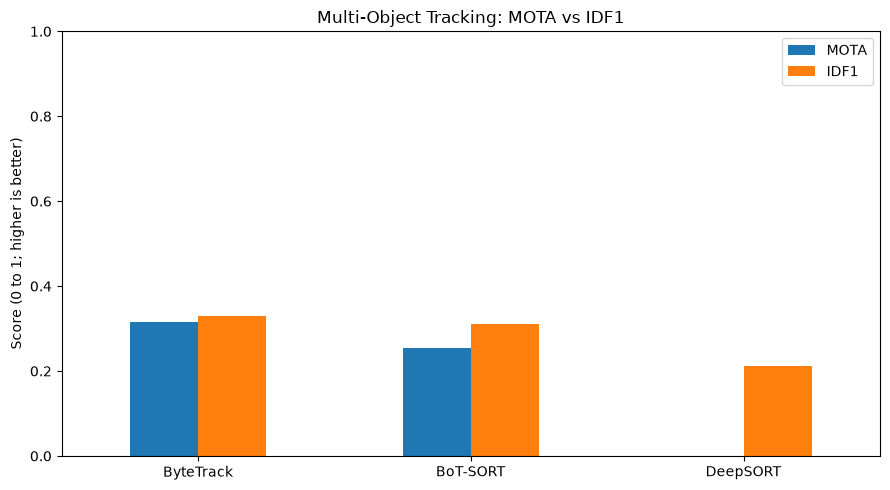

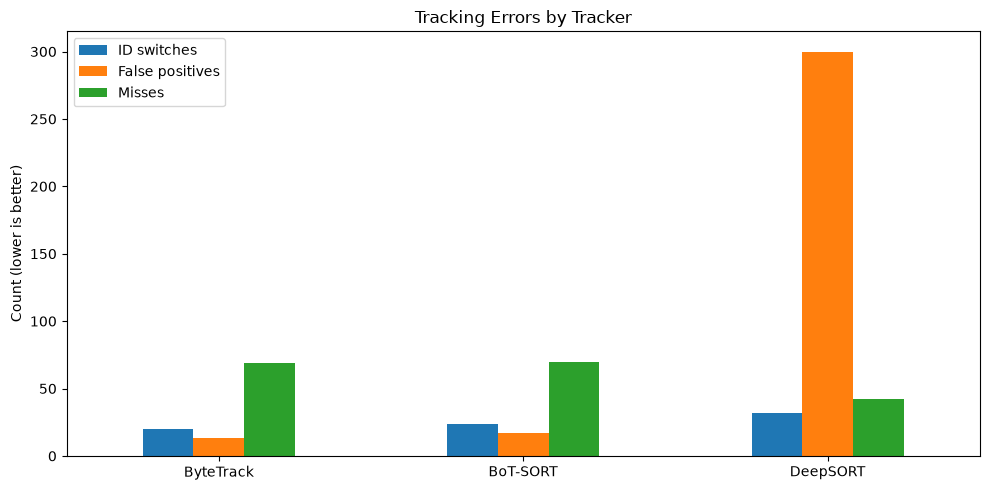

,Tracker,MOTA,IDF1,ID switches,False positives,Misses
0,ByteTrack,0.3154,0.3306,20,13,69
1,BoT-SORT,0.2550,0.3102,24,17,70
2,DeepSORT,-1.5101,0.2122,32,300,42


Comparison saved in: E:\proglint\main1\evaluation_results


In [33]:

import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"E:\proglint\main1")
RESULTS_DIR = PROJECT_DIR / "evaluation_results"

# Values from your completed evaluations
comparison = pd.DataFrame({
    "Tracker": ["ByteTrack", "BoT-SORT"],
    "MOTA": [0.315436, 0.255034],
    "IDF1": [0.330579, 0.310204],
    "ID switches": [20, 24],
    "False positives": [13, 17],
    "Misses": [69, 70]
})

# Load DeepSORT results
deep_path = RESULTS_DIR / "deepsort_metrics.csv"

if not deep_path.exists():
    raise FileNotFoundError(
        "Run the DeepSORT evaluation cell before comparing trackers."
    )

deep = pd.read_csv(deep_path, index_col=0)["value"]

comparison.loc[len(comparison)] = {
    "Tracker": "DeepSORT",
    "MOTA": float(deep["mota"]),
    "IDF1": float(deep["idf1"]),
    "ID switches": int(deep["num_switches"]),
    "False positives": int(deep["num_false_positives"]),
    "Misses": int(deep["num_misses"])
}

# ------------------------------------------
# Chart 1: MOTA and IDF1
# ------------------------------------------
ax = comparison.plot(
    x="Tracker",
    y=["MOTA", "IDF1"],
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Multi-Object Tracking: MOTA vs IDF1")
ax.set_ylabel("Score (0 to 1; higher is better)")
ax.set_xlabel("")
ax.legend(["MOTA", "IDF1"])
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "tracker_accuracy_comparison.png",
    dpi=150
)
plt.show()

# ------------------------------------------
# Chart 2: Tracking errors
# ------------------------------------------
ax = comparison.plot(
    x="Tracker",
    y=["ID switches", "False positives", "Misses"],
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Tracking Errors by Tracker")
ax.set_ylabel("Count (lower is better)")
ax.set_xlabel("")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "tracker_error_comparison.png",
    dpi=150
)
plt.show()

# ------------------------------------------
# Save and display comparison table
# ------------------------------------------
comparison.to_csv(
    RESULTS_DIR / "tracker_comparison.csv",
    index=False
)

display(comparison.round(4))

print("Comparison saved in:", RESULTS_DIR)

In [34]:

from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------
PROJECT_DIR = Path(r"E:\proglint\main1")
DATA_YAML = PROJECT_DIR / "evaluation_dataset" / "data.yaml"
RESULTS_DIR = PROJECT_DIR / "evaluation_results" / "yolo_model_comparison"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"Could not find data.yaml at: {DATA_YAML}\n"
        "Check the path to your existing evaluation dataset."
    )

print("Dataset config:", DATA_YAML)
print("GPU available:", torch.cuda.is_available())

# --------------------------------------------------
# 2. Model configurations
# --------------------------------------------------
model_names = [
    "yolov8n.pt",
    "yolov8s.pt",
    "yolov8m.pt"
]

comparison_results = []

# --------------------------------------------------
# 3. Evaluate each pretrained model
# --------------------------------------------------
for weights in model_names:
    model_name = Path(weights).stem

    print("\n" + "=" * 55)
    print(f"Evaluating {model_name}")
    print("=" * 55)

    model = YOLO(weights)

    metrics = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=640,
        batch=4,
        workers=0,
        device=0 if torch.cuda.is_available() else "cpu",
        classes=[0],       # Evaluate the person class
        conf=0.001,         # Low threshold for AP calculation
        iou=0.6,
        plots=True,
        verbose=False,
        project=str(RESULTS_DIR),
        name=model_name,
        exist_ok=True
    )

    box_metrics = metrics.box

    result_row = {
        "Model": model_name,
        "Precision": float(box_metrics.mp),
        "Recall": float(box_metrics.mr),
        "mAP50": float(box_metrics.map50),
        "mAP50-95": float(box_metrics.map),
        "Inference_ms_per_image": float(
            metrics.speed.get("inference", 0)
        )
    }

    comparison_results.append(result_row)

    print(f"Precision: {result_row['Precision']:.4f}")
    print(f"Recall:    {result_row['Recall']:.4f}")
    print(f"mAP@0.50:  {result_row['mAP50']:.4f}")
    print(f"mAP@0.50:0.95: {result_row['mAP50-95']:.4f}")
    print(
        "Inference time (ms/image): "
        f"{result_row['Inference_ms_per_image']:.2f}"
    )

# --------------------------------------------------
# 4. Save the comparison table
# --------------------------------------------------
comparison_df = pd.DataFrame(comparison_results)

csv_path = RESULTS_DIR / "yolo_model_metrics.csv"
comparison_df.to_csv(csv_path, index=False)

print("\n" + "=" * 55)
print("FINAL YOLO MODEL COMPARISON")
print("=" * 55)

display(comparison_df.round(4))

print("\nMetrics saved to:", csv_path)
print("Individual plots saved under:", RESULTS_DIR)


Dataset config: E:\proglint\main1\evaluation_dataset\data.yaml
GPU available: True

Evaluating yolov8n
Ultralytics 8.4.187  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 854.5±178.5 MB/s, size: 170.2 KB)
val: Scanning E:\proglint\main1\evaluation_dataset\labels\val.cache... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 13.1it/s 0.7s.2s
                   all         35        149      0.836      0.687      0.767       0.36
Speed: 0.4ms preprocess, 4.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to E:\proglint\main1\evaluation_results\yolo_model_comparison\yolov8n
Precision: 0.8365
Recall:    0.6867
mAP@0.50:  0.7667
mAP@0.50:0.95: 0.3598
Inference time (ms/image): 4

,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms_per_image
0,yolov8n,0.8365,0.6867,0.7667,0.3598,4.5685
1,yolov8s,0.8426,0.7547,0.7740,0.3708,8.8785
2,yolov8m,0.8923,0.7784,0.8175,0.3828,17.9301



Metrics saved to: E:\proglint\main1\evaluation_results\yolo_model_comparison\yolo_model_metrics.csv
Individual plots saved under: E:\proglint\main1\evaluation_results\yolo_model_comparison


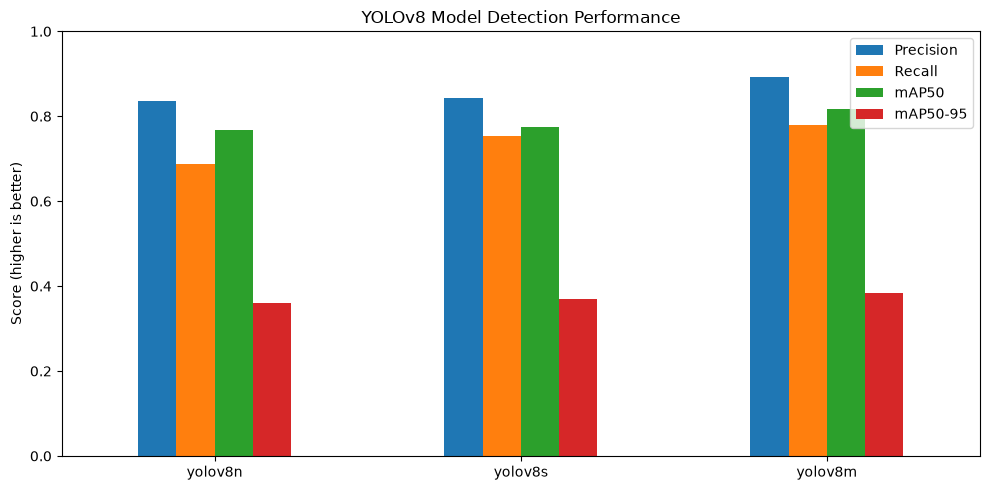

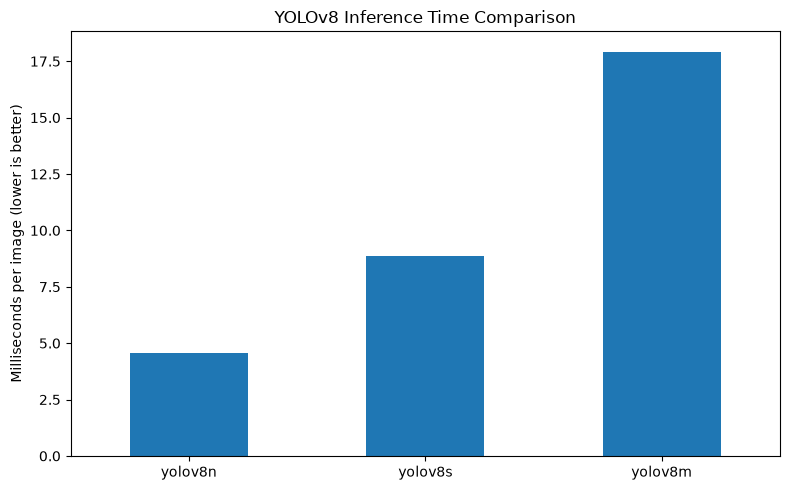

,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms_per_image
0,yolov8n,0.8365,0.6867,0.7667,0.3598,4.5685
1,yolov8s,0.8426,0.7547,0.7740,0.3708,8.8785
2,yolov8m,0.8923,0.7784,0.8175,0.3828,17.9301


In [35]:

import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = (
    Path(r"E:\proglint\main1")
    / "evaluation_results"
    / "yolo_model_comparison"
)

df = pd.read_csv(RESULTS_DIR / "yolo_model_metrics.csv")

# Chart 1: Detection accuracy
ax = df.plot(
    x="Model",
    y=["Precision", "Recall", "mAP50", "mAP50-95"],
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)
ax.set_title("YOLOv8 Model Detection Performance")
ax.set_ylabel("Score (higher is better)")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "yolo_accuracy_comparison.png",
    dpi=150
)
plt.show()

# Chart 2: Inference speed
ax = df.plot(
    x="Model",
    y="Inference_ms_per_image",
    kind="bar",
    figsize=(8, 5),
    rot=0,
    legend=False
)
ax.set_title("YOLOv8 Inference Time Comparison")
ax.set_ylabel("Milliseconds per image (lower is better)")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "yolo_speed_comparison.png",
    dpi=150
)
plt.show()

display(df.round(4))


In [36]:

from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

PROJECT_DIR = Path(r"E:\proglint\main1")
DATA_YAML = PROJECT_DIR / "evaluation_dataset" / "data.yaml"

RESULTS_DIR = (
    PROJECT_DIR
    / "evaluation_results"
    / "yolo_v9_v10_comparison"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

models_to_test = [
    "yolov9s.pt",
    "yolov10n.pt",
    "yolov10s.pt",
]

results_rows = []

for weights in models_to_test:
    name = Path(weights).stem
    print(f"\nEvaluating {name}...")

    model = YOLO(weights)

    metrics = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=640,
        batch=2,
        workers=0,
        device=0 if torch.cuda.is_available() else "cpu",
        classes=[0],
        conf=0.001,
        plots=True,
        verbose=False,
        project=str(RESULTS_DIR),
        name=name,
        exist_ok=True
    )

    results_rows.append({
        "Model": name,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "Inference_ms_per_image": float(
            metrics.speed.get("inference", 0)
        )
    })

    print("Recall:", round(float(metrics.box.mr), 4))
    print("mAP50:", round(float(metrics.box.map50), 4))

df = pd.DataFrame(results_rows)
output_csv = RESULTS_DIR / "yolo_v9_v10_metrics.csv"
df.to_csv(output_csv, index=False)

display(df.round(4))
print("Saved:", output_csv)



Evaluating yolov9s...
Ultralytics 8.4.187  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv9s summary (fused): 197 layers, 7,198,048 parameters, 0 gradients, 26.9 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1656.0±178.6 MB/s, size: 171.6 KB)
val: Scanning E:\proglint\main1\evaluation_dataset\labels\val.cache... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 18.3it/s 1.0s0.1s
                   all         35        149      0.884      0.772      0.787      0.386
Speed: 0.4ms preprocess, 17.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to E:\proglint\main1\evaluation_results\yolo_v9_v10_comparison\yolov9s
Recall: 0.7718
mAP50: 0.7869

Evaluating yolov10n...
Ultralytics 8.4.187  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv10n summary 

,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms_per_image
0,yolov9s,0.8841,0.7718,0.7869,0.3863,17.2039
1,yolov10n,0.8710,0.7251,0.8002,0.3817,9.7131
2,yolov10s,0.8857,0.7804,0.7873,0.3847,9.7276


Saved: E:\proglint\main1\evaluation_results\yolo_v9_v10_comparison\yolo_v9_v10_metrics.csv


,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms_per_image
0,YOLOv8n,0.8365,0.6867,0.7667,0.3598,4.5685
1,YOLOv8s,0.8426,0.7547,0.7740,0.3708,8.8785
2,YOLOv8m,0.8923,0.7784,0.8175,0.3828,17.9301
3,YOLOv9s,0.8841,0.7718,0.7869,0.3863,17.2039
4,YOLOv10n,0.8710,0.7251,0.8002,0.3817,9.7131
5,YOLOv10s,0.8857,0.7804,0.7873,0.3847,9.7276


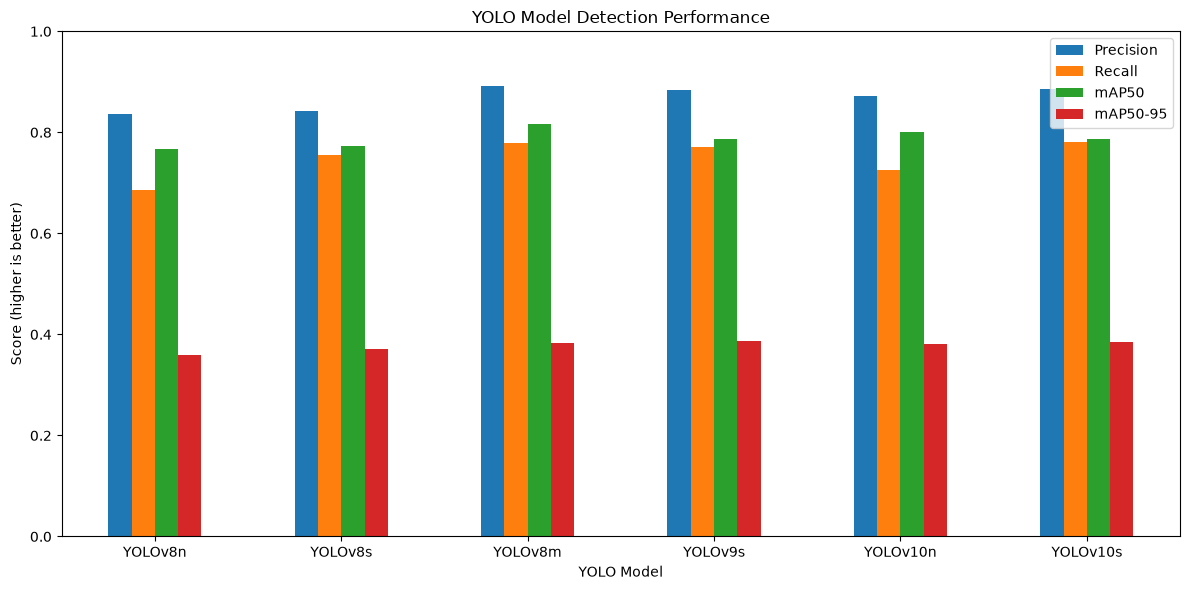

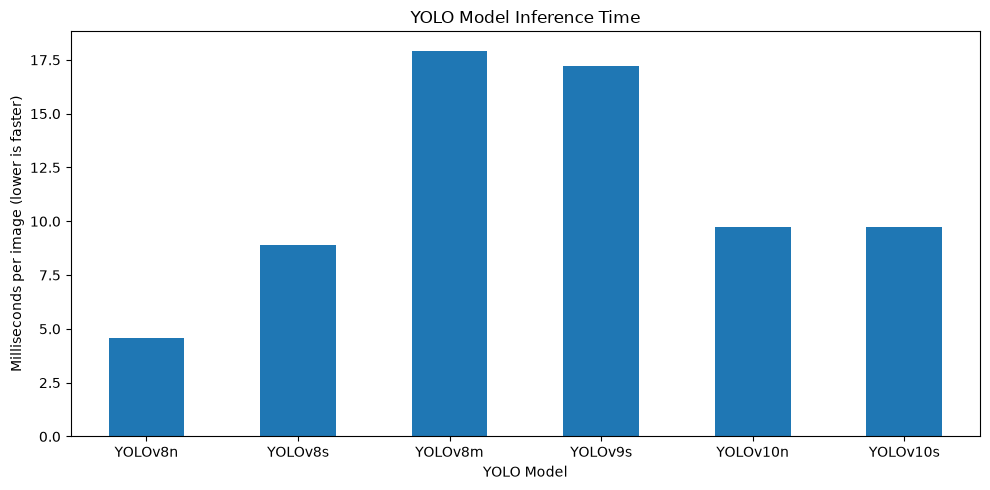

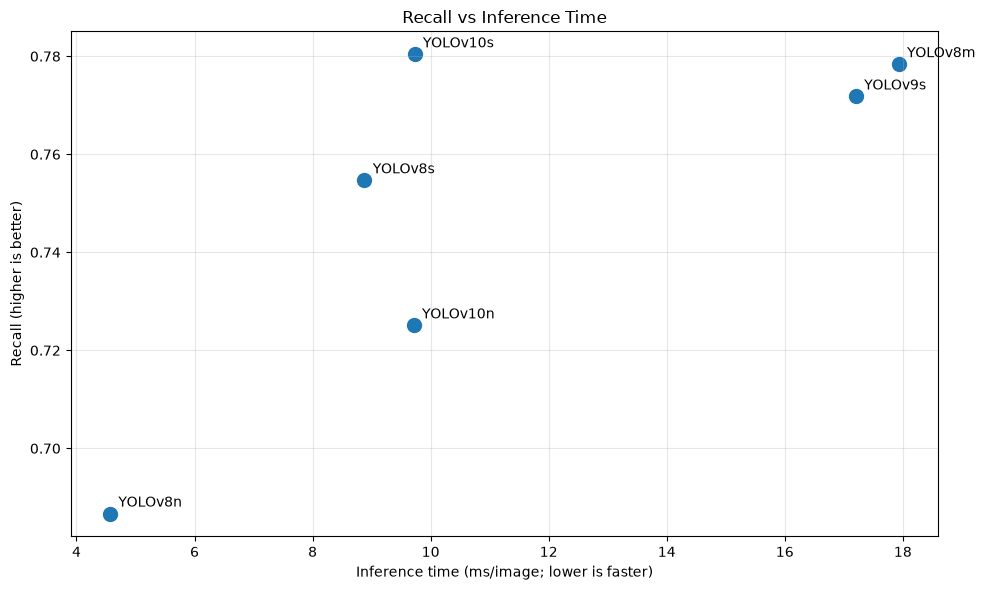

Models ranked by recall, with faster inference preferred in ties:


,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms_per_image
0,YOLOv10s,0.8857,0.7804,0.7873,0.3847,9.7276
1,YOLOv8m,0.8923,0.7784,0.8175,0.3828,17.9301
2,YOLOv9s,0.8841,0.7718,0.7869,0.3863,17.2039
3,YOLOv8s,0.8426,0.7547,0.7740,0.3708,8.8785
4,YOLOv10n,0.8710,0.7251,0.8002,0.3817,9.7131
5,YOLOv8n,0.8365,0.6867,0.7667,0.3598,4.5685


Fastest model: YOLOv8n
Best recall model: YOLOv10s


In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------
# 1. Enter the evaluation results
# ---------------------------------------------
data = [
    {
        "Model": "YOLOv8n",
        "Precision": 0.8365,
        "Recall": 0.6867,
        "mAP50": 0.7667,
        "mAP50-95": 0.3598,
        "Inference_ms_per_image": 4.5685
    },
    {
        "Model": "YOLOv8s",
        "Precision": 0.8426,
        "Recall": 0.7547,
        "mAP50": 0.7740,
        "mAP50-95": 0.3708,
        "Inference_ms_per_image": 8.8785
    },
    {
        "Model": "YOLOv8m",
        "Precision": 0.8923,
        "Recall": 0.7784,
        "mAP50": 0.8175,
        "mAP50-95": 0.3828,
        "Inference_ms_per_image": 17.9301
    },
    {
        "Model": "YOLOv9s",
        "Precision": 0.8841,
        "Recall": 0.7718,
        "mAP50": 0.7869,
        "mAP50-95": 0.3863,
        "Inference_ms_per_image": 17.2039
    },
    {
        "Model": "YOLOv10n",
        "Precision": 0.8710,
        "Recall": 0.7251,
        "mAP50": 0.8002,
        "mAP50-95": 0.3817,
        "Inference_ms_per_image": 9.7131
    },
    {
        "Model": "YOLOv10s",
        "Precision": 0.8857,
        "Recall": 0.7804,
        "mAP50": 0.7873,
        "mAP50-95": 0.3847,
        "Inference_ms_per_image": 9.7276
    }
]

df = pd.DataFrame(data)

display(df.round(4))

# ---------------------------------------------
# 2. Plot detection metrics
# ---------------------------------------------
ax = df.plot(
    x="Model",
    y=["Precision", "Recall", "mAP50", "mAP50-95"],
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

ax.set_title("YOLO Model Detection Performance")
ax.set_ylabel("Score (higher is better)")
ax.set_xlabel("YOLO Model")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# ---------------------------------------------
# 3. Plot inference speed
# ---------------------------------------------
ax = df.plot(
    x="Model",
    y="Inference_ms_per_image",
    kind="bar",
    figsize=(10, 5),
    rot=0,
    legend=False
)

ax.set_title("YOLO Model Inference Time")
ax.set_ylabel("Milliseconds per image (lower is faster)")
ax.set_xlabel("YOLO Model")
plt.tight_layout()
plt.show()

# ---------------------------------------------
# 4. Plot recall versus inference time
# ---------------------------------------------
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Inference_ms_per_image"],
    df["Recall"],
    s=100
)

for _, row in df.iterrows():
    plt.annotate(
        row["Model"],
        (
            row["Inference_ms_per_image"],
            row["Recall"]
        ),
        xytext=(6, 5),
        textcoords="offset points"
    )

plt.title("Recall vs Inference Time")
plt.xlabel("Inference time (ms/image; lower is faster)")
plt.ylabel("Recall (higher is better)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------
# 5. Rank models by recall and speed
# ---------------------------------------------
ranking = df.sort_values(
    by=["Recall", "Inference_ms_per_image"],
    ascending=[False, True]
).reset_index(drop=True)

print("Models ranked by recall, with faster inference preferred in ties:")
display(ranking.round(4))

# Fastest model
fastest = df.loc[df["Inference_ms_per_image"].idxmin()]

# Best recall model
best_recall = df.loc[df["Recall"].idxmax()]

print(f"Fastest model: {fastest['Model']}")
print(f"Best recall model: {best_recall['Model']}")